## 1. Setup
Import the libraries needed for this notebook.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

plt.style.use("default")
sns.set_style("whitegrid")

## 2. EDA Helper Functions
Reusable functions used to explore the dataset.

In [2]:
# Dataset Overview
def dataset_overview(df):
    """
    Displays basic information about the dataset.
    """

    print("=" * 80)
    print("DATASET OVERVIEW")
    print("=" * 80)

    print(f"\nRows                : {df.shape[0]}")
    print(f"Columns             : {df.shape[1]}")

    print("\nColumn Names")
    print("-" * 80)

    for col in df.columns:
        print(col)

    print("\nDataset Info")
    print("-" * 80)
    print(df.info())

    print("\nStatistical Summary (Numerical)")
    print("-" * 80)
    print(df.describe().T)

    print("\nStatistical Summary (Categorical)")
    print("-" * 80)
    print(df.describe(include="object").T)

  # Column Analysis

def column_analysis(df):
    """
    Displays metadata for every column.
    """

    print("\n")
    print("=" * 80)
    print("COLUMN ANALYSIS")
    print("=" * 80)

    total_rows = len(df)

    for col in df.columns:

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        dtype = df[col].dtype
        missing = df[col].isna().sum()
        unique = df[col].nunique(dropna=True)

        print(f"Data Type          : {dtype}")
        if unique <= 20:
            print(df[col].unique())
        else:
            print(df[col].unique()[:20])
            print(f"\nshowing first 20 of {unique} unique values")

        if unique >= 0.95 * total_rows:
            print("Possible Identifier Column")
# Missing Value Analysis
def missing_value_analysis(df):
    print("\n")
    print("=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)

    missing = df.isnull().sum()

    missing_percent = (missing / len(df)) * 100

    missing_df = pd.DataFrame({

        "Missing Count": missing,
        "Missing Percentage": missing_percent

    })

    print(missing_df)
    """
    # Heatmap
    plt.figure(figsize=(12,6))
    sns.heatmap(df.isnull(),cbar=True,cmap="viridis")
    plt.title("Missing Value Heatmap")
    plt.show()"""

    #Bar Chart
    plt.figure(figsize=(12,5))
    missing_percent.plot(kind="bar")
    plt.ylabel("Missing Percentage")
    plt.title("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.show()

# Duplicate values analysis
def duplicate_analysis(df):
    """
    Displays duplicate row statistics.
    """

    print("\n")
    print("=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    duplicates = df.duplicated().sum()

    duplicate_percent = (duplicates / len(df)) * 100

    print(f"Duplicate Rows       : {duplicates}")

    print(f"Duplicate Percentage : {duplicate_percent:.2f}%")

    plt.figure(figsize=(4,4))

    plt.pie(

        [len(df)-duplicates, duplicates],

        labels=["Unique Rows", "Duplicate Rows"],

        autopct="%1.1f%%"

    )

    plt.title("Duplicate Row Distribution")

    plt.show()
# Numerical and Categorical analysis
from scipy import stats

def numerical_analysis(df):
    """
    Performs analysis on all numerical columns.
    """

    print("\n")
    print("=" * 80)
    print("NUMERICAL FEATURE ANALYSIS")
    print("=" * 80)

    for col in df.columns:

        # --------------------------------------------
        # Numeric column OR object storing numbers
        # --------------------------------------------

        if pd.api.types.is_numeric_dtype(df[col]):
            temp = df[col].dropna()

        else:
            temp = pd.to_numeric(df[col], errors="coerce").dropna()

            if len(temp) < 0.9 * df[col].notna().sum():
                continue

        if temp.empty:
            continue

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        print(f"Mean       : {temp.mean():.3f}")
        print(f"Median     : {temp.median():.3f}")
        print(f"Std Dev    : {temp.std():.3f}")
        print(f"Variance   : {temp.var():.3f}")
        print(f"Skewness   : {temp.skew():.3f}")
        print(f"Kurtosis   : {temp.kurtosis():.3f}")

        # --------------------------
        # Histogram
        # --------------------------

        plt.figure(figsize=(6,4))
        plt.hist(temp,bins=30)

        plt.title(f"Histogram : {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

        # --------------------------
        # Boxplot
        # --------------------------

        plt.figure(figsize=(6,2))
        sns.boxplot(x=temp)

        plt.title(f"Boxplot : {col}")
        plt.show()
        """
        # --------------------------
        # QQ Plot
        # --------------------------

        plt.figure(figsize=(5,5))
        stats.probplot(temp, dist="norm", plot=plt)

        plt.title(f"QQ Plot : {col}")
        plt.show()"""

        # --------------------------
        # Outliers (IQR)
        # --------------------------

        q1 = temp.quantile(0.25)
        q3 = temp.quantile(0.75)

        iqr = q3-q1

        lower = q1 - 1.5*iqr
        upper = q3 + 1.5*iqr

        outliers = ((temp<lower) | (temp>upper)).sum()

        print(f"Outliers Detected : {outliers}")

def categorical_analysis(df):
    """
    Performs analysis on categorical columns.
    """

    print("\n")
    print("=" * 80)
    print("CATEGORICAL FEATURE ANALYSIS")
    print("=" * 80)
    total_rows=len(df.columns)
    for col in df.columns:

        if pd.api.types.is_numeric_dtype(df[col]):
            continue

        temp = pd.to_numeric(df[col], errors="coerce")

        if temp.notna().sum() >= 0.9 * df[col].notna().sum():
            continue

        unique = df[col].nunique(dropna=True)

        print("\n" + "-"*80)
        print(f"Column : {col}")
        print("-"*80)

        print(f"Unique Categories : {unique}")

        counts = df[col].value_counts(dropna=False)
        if unique < 0.80 * total_rows:
          if unique <= 20:
              print(counts)
          else:
              print(counts.head(20))
              print(f"\nShowing Top 20 categories out of {unique}")

          plt.figure(figsize=(8,4))

          counts.plot(kind="bar")

          plt.title(col)
          plt.ylabel("Count")
          plt.xticks(rotation=45)

          plt.show()

def correlation_analysis(df):
    """
    Correlation analysis of numerical columns.
    """

    print("\n")
    print("=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.shape[1] < 2:
        print("Not enough numerical columns.")
        return []

    corr = numeric_df.corr()

    plt.figure(figsize=(10,8))

    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.show()

    print("\nHighly Correlated Feature Pairs")

    high_corr=[]

    cols=corr.columns

    for i in range(len(cols)):
        for j in range(i+1,len(cols)):

            if abs(corr.iloc[i,j])>=0.8:

                print(f"{cols[i]}, {cols[j]} = {corr.iloc[i,j]}")

                high_corr.append((cols[i],cols[j],corr.iloc[i,j]))

    return high_corr

def target_analysis(df,task,target):

    print("\n")
    print("="*80)
    print("TARGET ANALYSIS")
    print("="*80)

    if target is None:
        print("No target provided as parameter!")
        return

    if task.lower()=="classification":

        print(df[target].value_counts())

        plt.figure(figsize=(6,4))

        df[target].value_counts().plot(kind="bar")

        plt.title("Class Distribution")

        plt.show()

    elif task.lower()=="regression":

        print(df[target].describe())

        plt.figure(figsize=(6,4))

        plt.hist(df[target].dropna(),bins=30)

        plt.title("Target Distribution")

        plt.show()

def eda_summary(df, high_corr):

    print("\n")
    print("="*80)
    print("FINAL EDA SUMMARY")
    print("="*80)

    print(f"Rows                     : {df.shape[0]}")
    print(f"Columns                  : {df.shape[1]}")

    print(f"Numerical Columns        : {len(df.select_dtypes(include=np.number).columns)}")

    print(f"Categorical Columns      : {len(df.select_dtypes(exclude=np.number).columns)}")

    print(f"Duplicate Rows           : {df.duplicated().sum()}")

    print(f"Columns with Missing     : {(df.isnull().sum()>0).sum()}")

    print(f"Highly Correlated Pairs  : {len(high_corr)}")

    print("\nEDA Completed Successfully.")



In [3]:
def tabular_eda(df, task, target=None):

    dataset_overview(df)

    column_analysis(df)

    missing_value_analysis(df)

    duplicate_analysis(df)

    numerical_analysis(df)

    categorical_analysis(df)

    high_corr = correlation_analysis(df)

    target_analysis(df, task, target)

    eda_summary(df, high_corr)

## 3. Load Dataset

In [ ]:
train = pd.read_csv("datasets\loan\train.csv")
test = pd.read_csv("Experiment1\datasets\loan\test.csv")

print(train.shape)
print(test.shape)

(30000, 24)
(20000, 23)


## 4. Exploratory Data Analysis (Before Cleaning)

DATASET OVERVIEW

Rows                : 30000
Columns             : 24

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price
Loan Sanction Amount (USD)

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  30000 non-null  object 
 1   Name                         30000 non-null  object 
 2   Gender                       29947 no

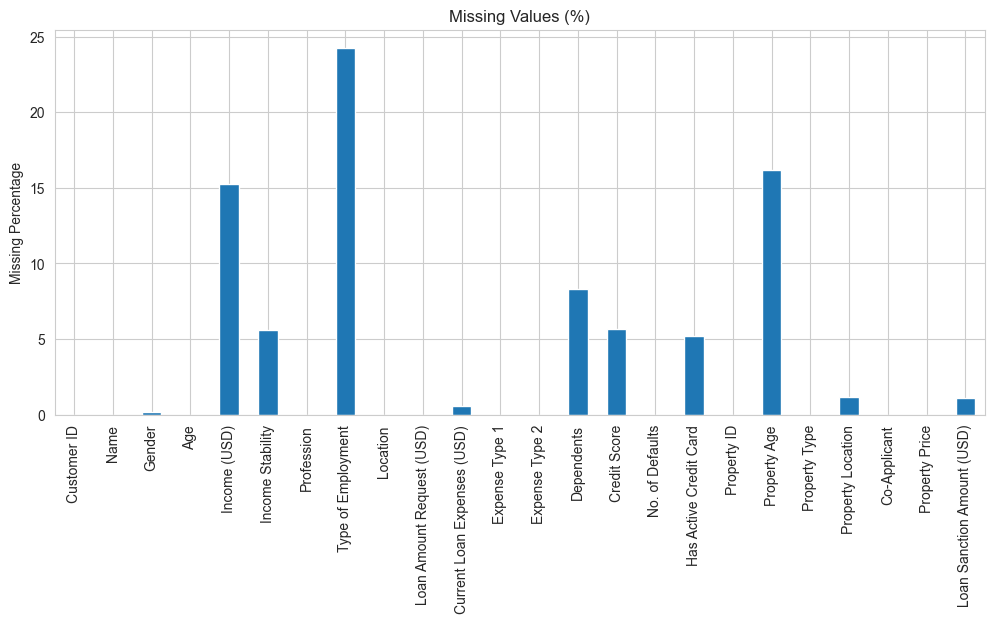



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


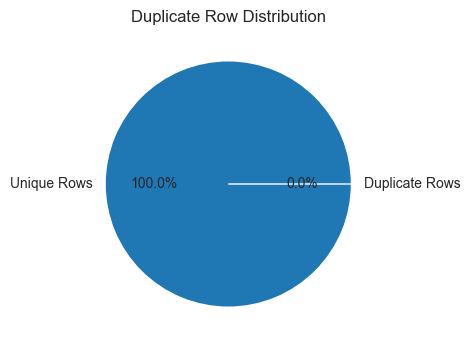



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 40.092
Median     : 40.000
Std Dev    : 16.045
Variance   : 257.446
Skewness   : 0.046
Kurtosis   : -1.382


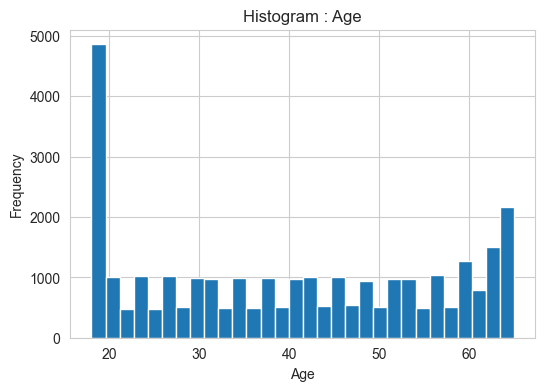

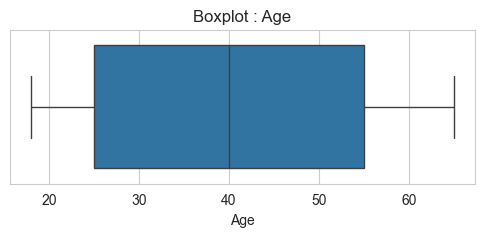

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2630.574
Median     : 2222.435
Std Dev    : 11262.724
Variance   : 126848948.069
Skewness   : 154.002
Kurtosis   : 24259.669


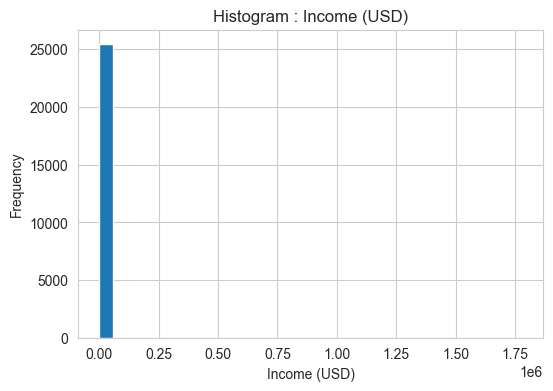

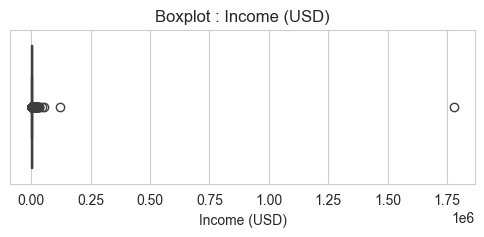

Outliers Detected : 1124

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88826.334
Median     : 75128.075
Std Dev    : 59536.950
Variance   : 3544648368.253
Skewness   : 1.260
Kurtosis   : 2.103


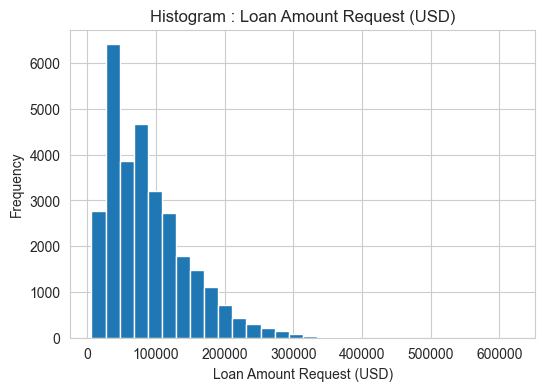

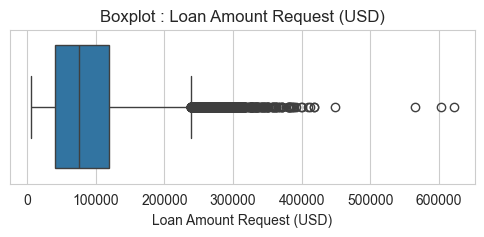

Outliers Detected : 752

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 400.937
Median     : 375.205
Std Dev    : 242.545
Variance   : 58828.259
Skewness   : 0.044
Kurtosis   : 10.751


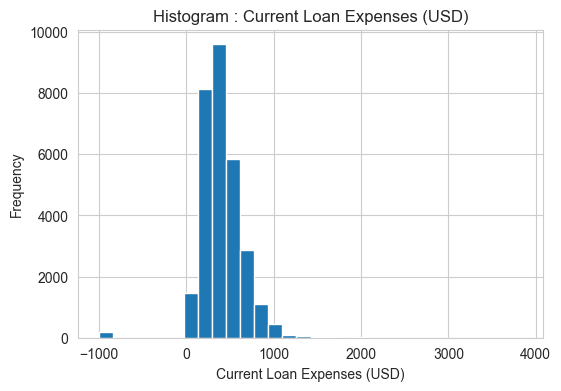

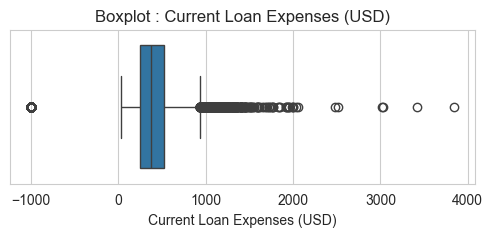

Outliers Detected : 857

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.253
Median     : 2.000
Std Dev    : 0.951
Variance   : 0.905
Skewness   : 0.805
Kurtosis   : 1.399


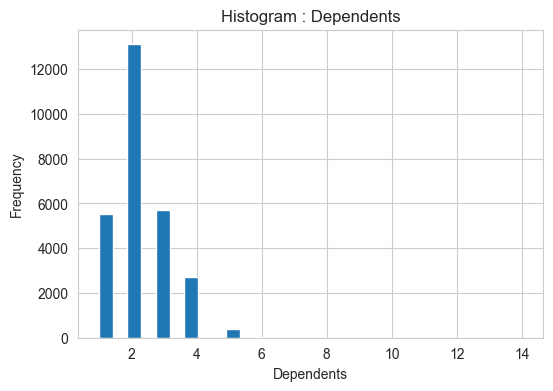

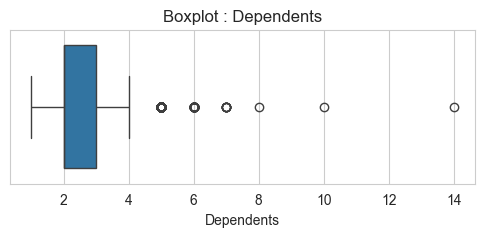

Outliers Detected : 432

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 739.885
Median     : 739.820
Std Dev    : 72.164
Variance   : 5207.621
Skewness   : -0.020
Kurtosis   : -0.985


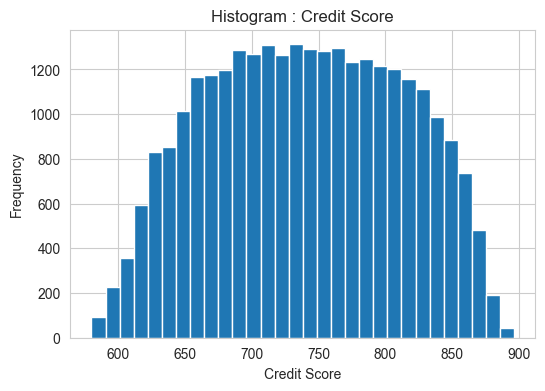

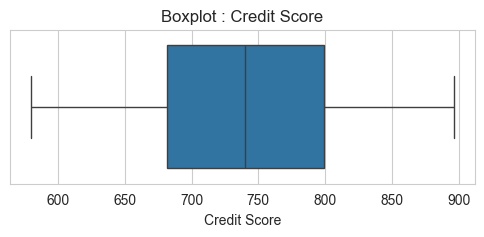

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.194
Median     : 0.000
Std Dev    : 0.395
Variance   : 0.156
Skewness   : 1.548
Kurtosis   : 0.397


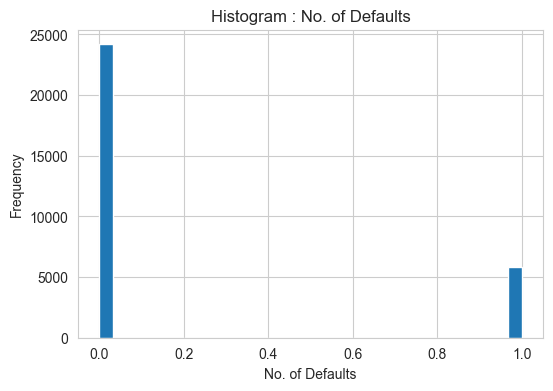

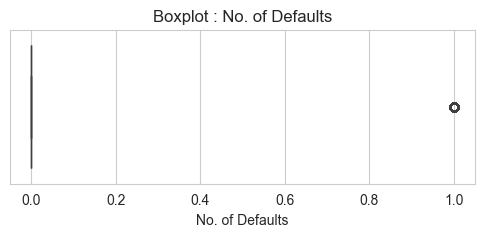

Outliers Detected : 5818

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.935
Median     : 504.000
Std Dev    : 288.158
Variance   : 83035.082
Skewness   : -0.011
Kurtosis   : -1.203


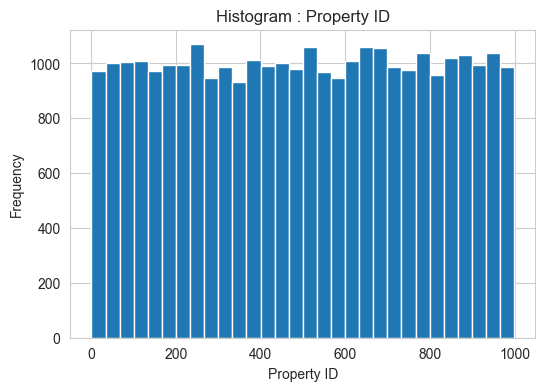

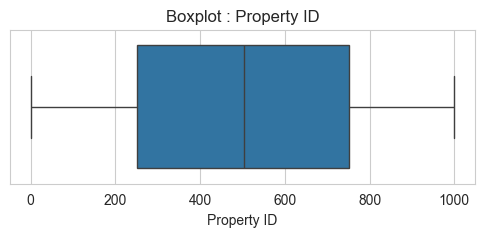

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2631.119
Median     : 2223.250
Std Dev    : 11322.677
Variance   : 128203014.453
Skewness   : 153.220
Kurtosis   : 24008.677


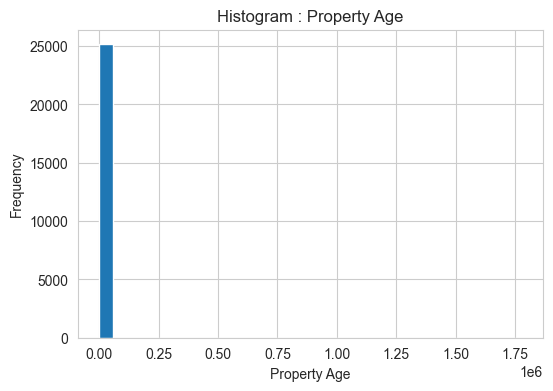

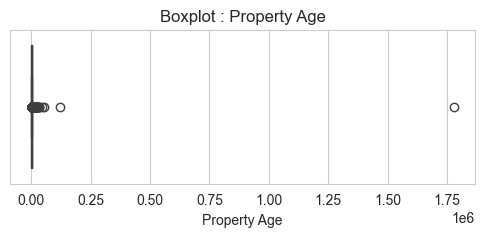

Outliers Detected : 1105

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.460
Median     : 2.000
Std Dev    : 1.119
Variance   : 1.251
Skewness   : 0.051
Kurtosis   : -1.359


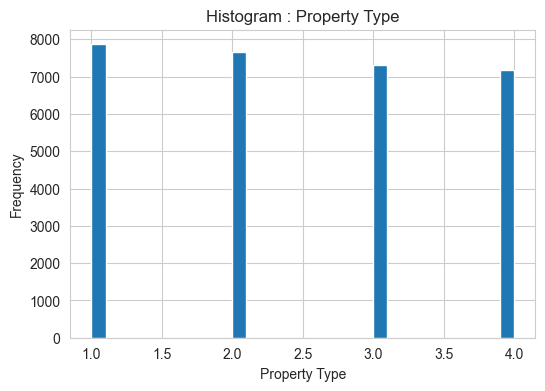

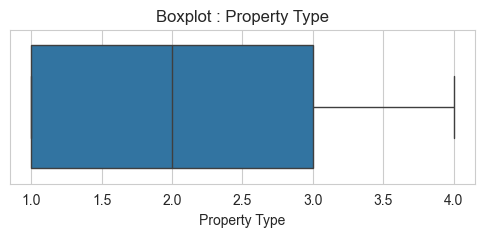

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : -4.744
Median     : 1.000
Std Dev    : 74.615
Variance   : 5567.337
Skewness   : -13.251
Kurtosis   : 173.598


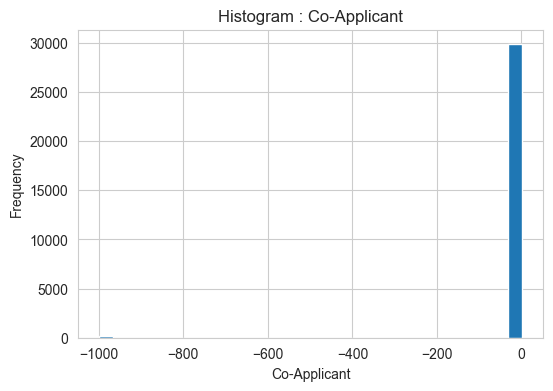

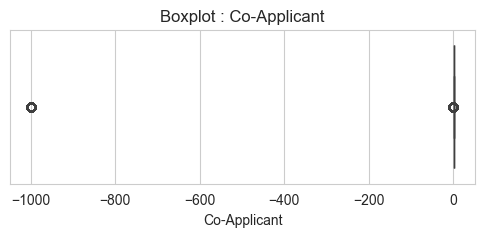

Outliers Detected : 4484

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 131759.680
Median     : 109993.610
Std Dev    : 93549.548
Variance   : 8751517950.503
Skewness   : 1.417
Kurtosis   : 3.149


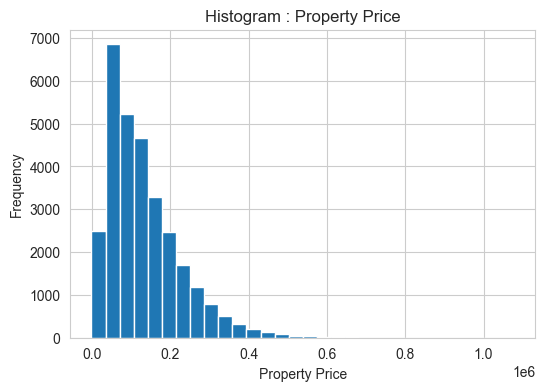

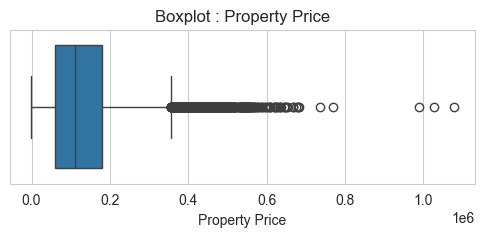

Outliers Detected : 863

--------------------------------------------------------------------------------
Column : Loan Sanction Amount (USD)
--------------------------------------------------------------------------------
Mean       : 47649.342
Median     : 35209.395
Std Dev    : 48221.147
Variance   : 2325278987.676
Skewness   : 1.230
Kurtosis   : 1.760


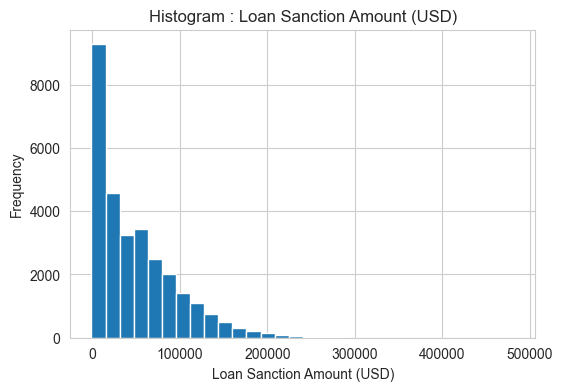

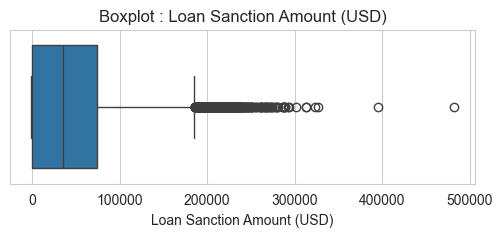

Outliers Detected : 438


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
M      15053
F      14894
NaN       53
Name: count, dtype: int64


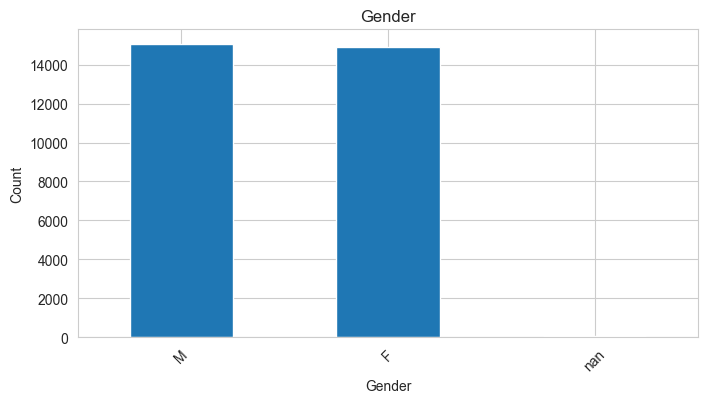


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     25751
High     2566
NaN      1683
Name: count, dtype: int64


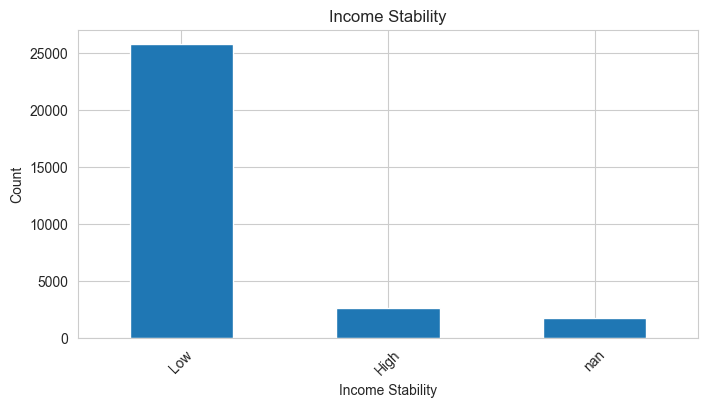


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 8
Profession
Working                 16926
Commercial associate     7962
Pensioner                2740
State servant            2366
Unemployed                  2
Businessman                 2
Student                     1
Maternity leave             1
Name: count, dtype: int64


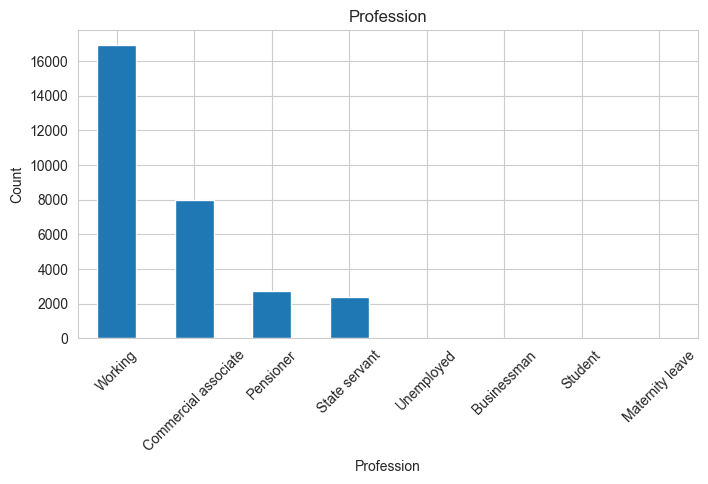


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
NaN                      7270
Laborers                 5578
Sales staff              3736
Core staff               3230
Managers                 2495
Drivers                  1606
Accountants              1379
High skill tech staff    1307
Medicine staff            864
Security staff            579
Cooking staff             566
Private service staff     342
Cleaning staff            341
Low-skill Laborers        162
Secretaries               161
Waiters/barmen staff      149
Realty agents              86
IT staff                   77
HR staff                   72
Name: count, dtype: int64


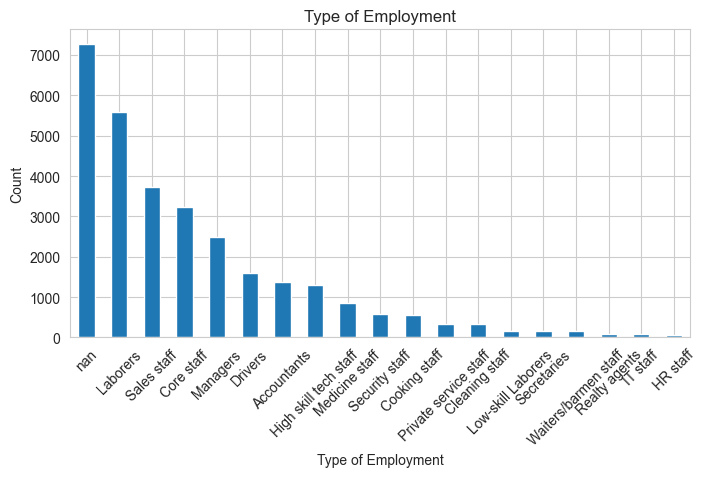


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    21563
Rural          5338
Urban          3099
Name: count, dtype: int64


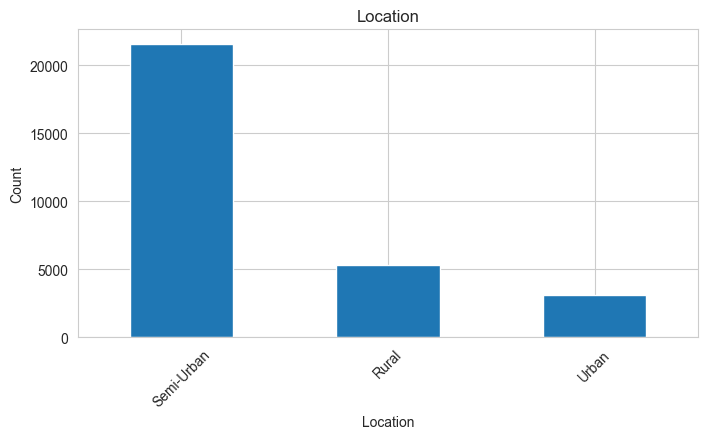


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    19214
Y    10786
Name: count, dtype: int64


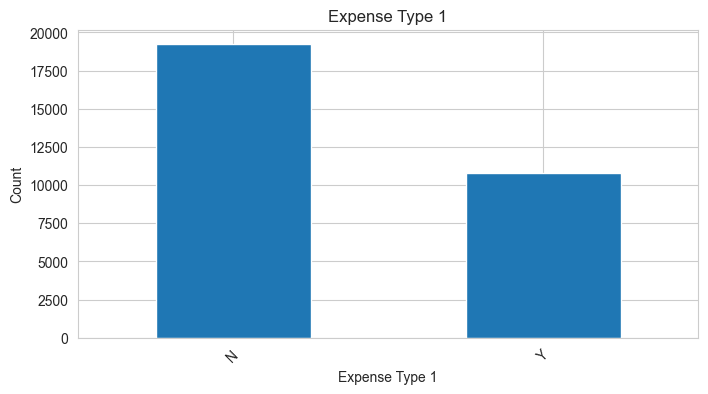


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    20180
N     9820
Name: count, dtype: int64


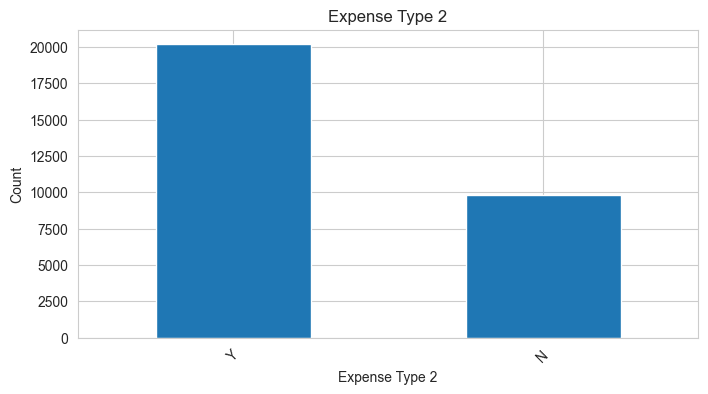


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         9771
Inactive       9466
Unpossessed    9197
NaN            1566
Name: count, dtype: int64


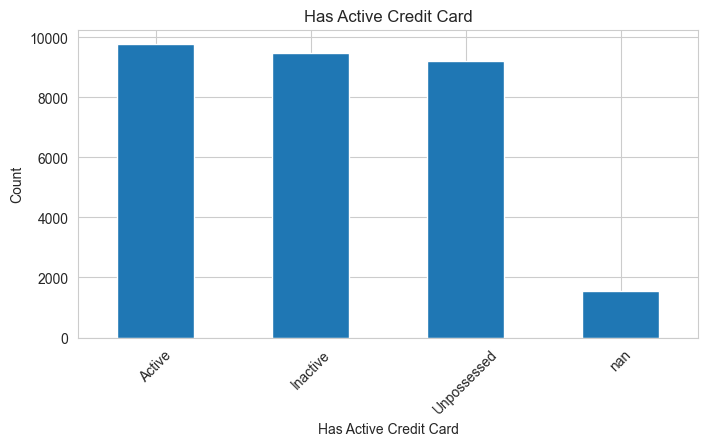


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    10387
Rural         10041
Urban          9216
NaN             356
Name: count, dtype: int64


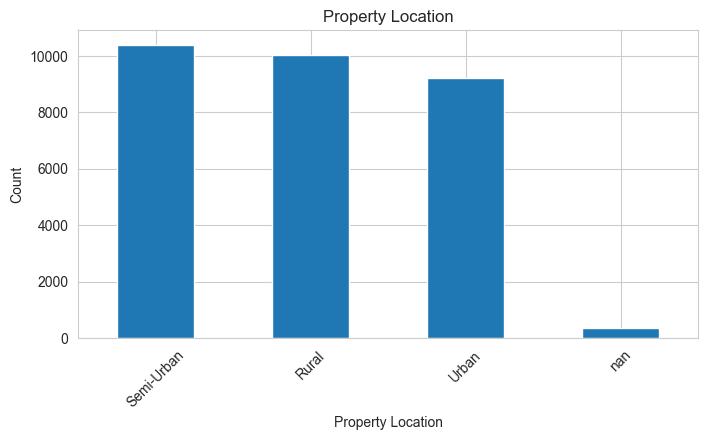



CORRELATION ANALYSIS


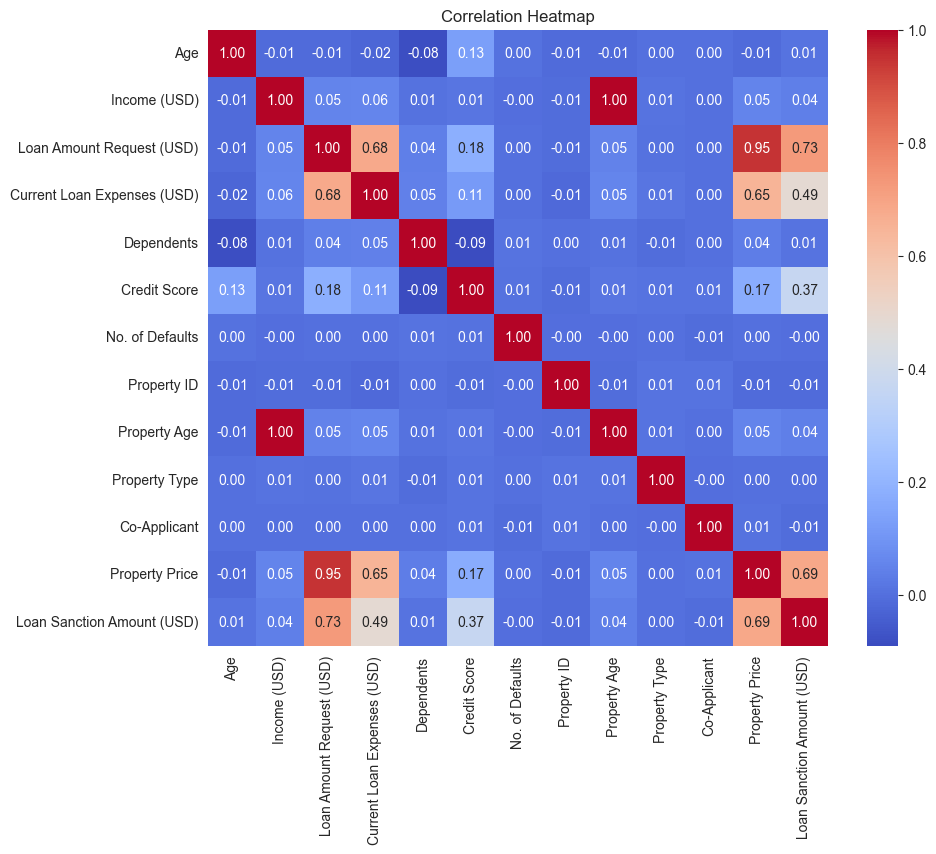


Highly Correlated Feature Pairs
Income (USD), Property Age = 1.0
Loan Amount Request (USD), Property Price = 0.9483497026229606


TARGET ANALYSIS
count     29660.000000
mean      47649.342208
std       48221.146686
min        -999.000000
25%           0.000000
50%       35209.395000
75%       74261.250000
max      481907.320000
Name: Loan Sanction Amount (USD), dtype: float64


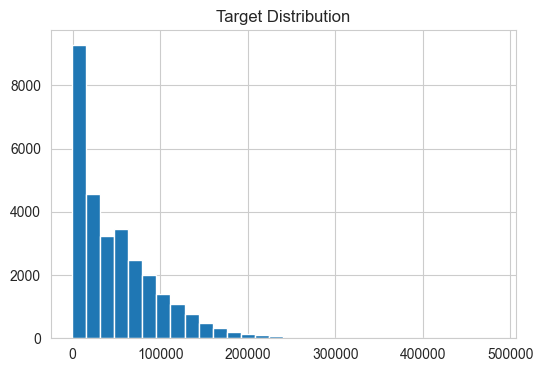



FINAL EDA SUMMARY
Rows                     : 30000
Columns                  : 24
Numerical Columns        : 13
Categorical Columns      : 11
Duplicate Rows           : 0
Columns with Missing     : 11
Highly Correlated Pairs  : 2

EDA Completed Successfully.


In [5]:
tabular_eda(train, "regression","Loan Sanction Amount (USD)")

DATASET OVERVIEW

Rows                : 20000
Columns             : 23

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  20000 non-null  object 
 1   Name                         20000 non-null  object 
 2   Gender                       19969 non-null  object 
 3   Age   

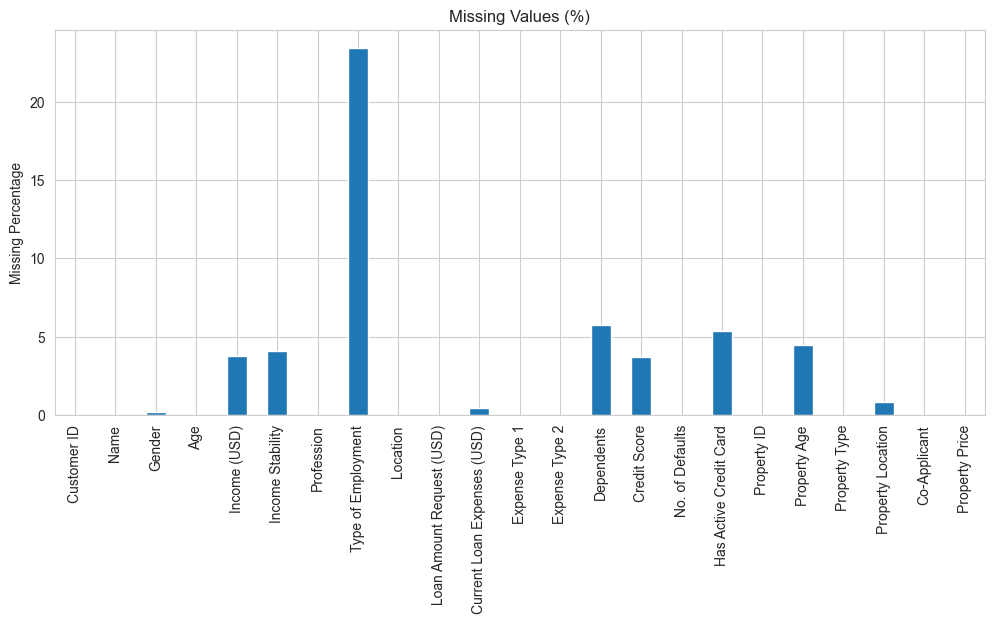



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


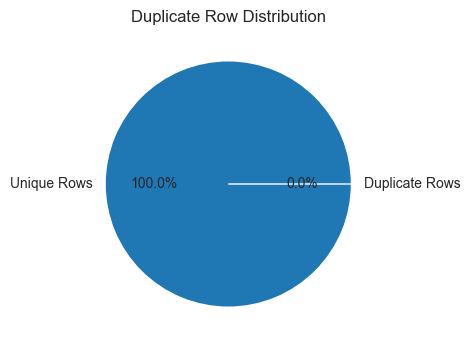



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 39.941
Median     : 40.000
Std Dev    : 16.098
Variance   : 259.133
Skewness   : 0.055
Kurtosis   : -1.387


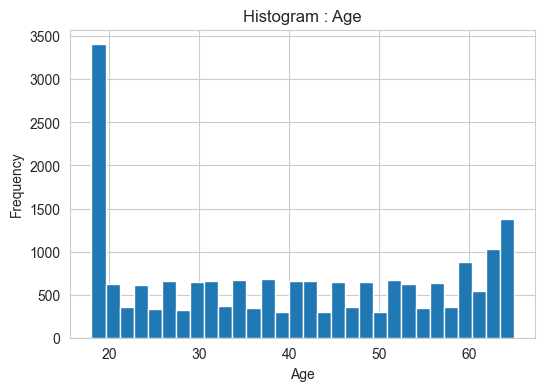

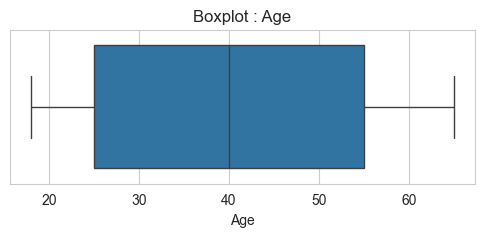

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2536.995
Median     : 2224.590
Std Dev    : 1415.909
Variance   : 2004797.738
Skewness   : 3.410
Kurtosis   : 31.052


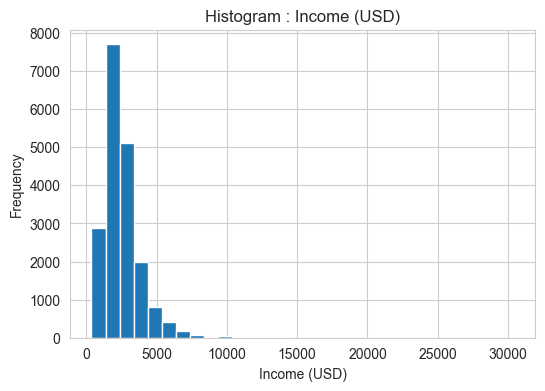

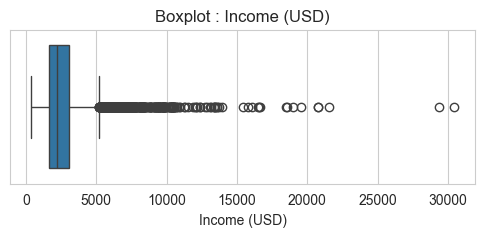

Outliers Detected : 831

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88859.077
Median     : 74565.990
Std Dev    : 60007.334
Variance   : 3600880094.522
Skewness   : 1.278
Kurtosis   : 1.971


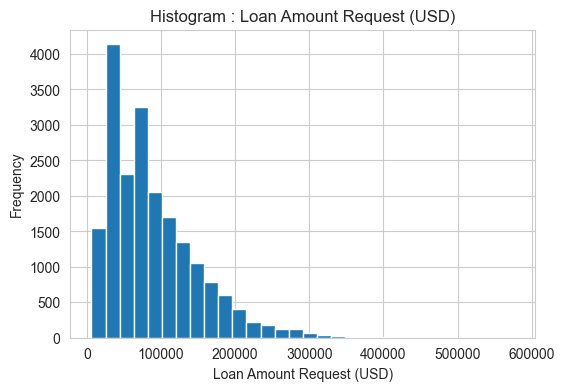

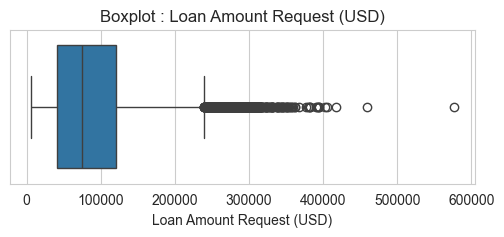

Outliers Detected : 511

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 408.462
Median     : 374.000
Std Dev    : 215.847
Variance   : 46589.725
Skewness   : 1.378
Kurtosis   : 5.452


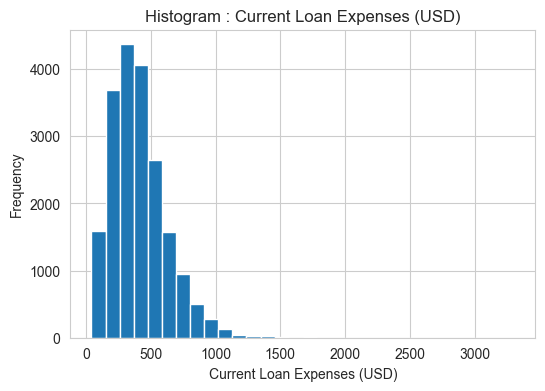

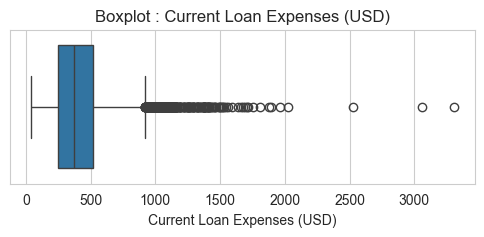

Outliers Detected : 486

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.251
Median     : 2.000
Std Dev    : 0.953
Variance   : 0.909
Skewness   : 0.807
Kurtosis   : 1.470


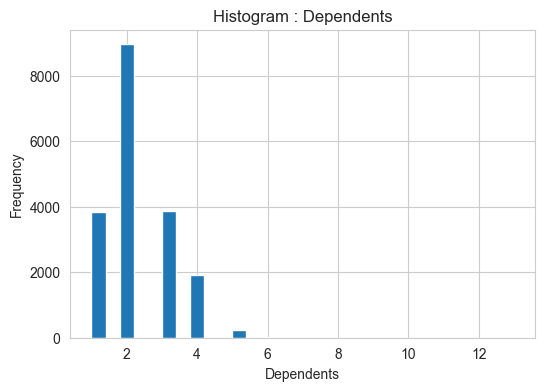

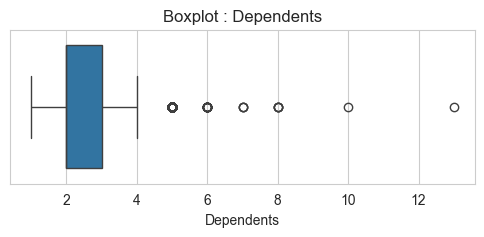

Outliers Detected : 275

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 738.822
Median     : 739.300
Std Dev    : 72.407
Variance   : 5242.702
Skewness   : -0.012
Kurtosis   : -0.991


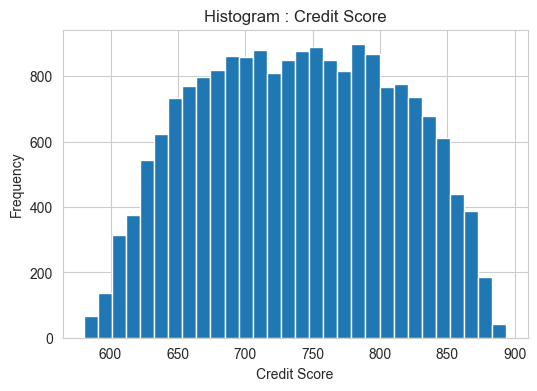

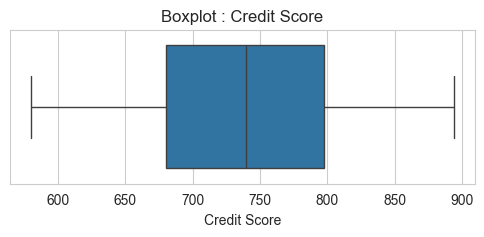

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.190
Median     : 0.000
Std Dev    : 0.392
Variance   : 0.154
Skewness   : 1.585
Kurtosis   : 0.511


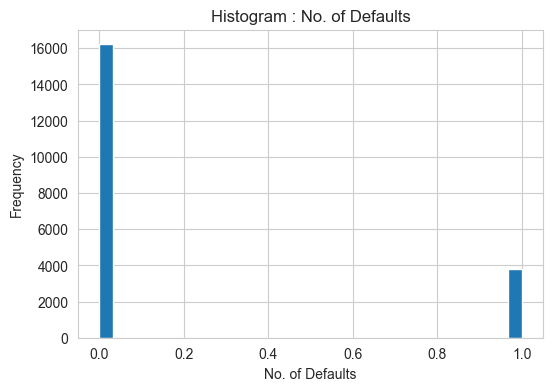

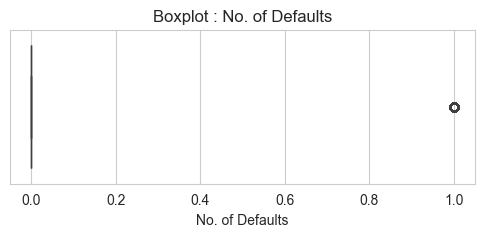

Outliers Detected : 3790

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.024
Median     : 501.000
Std Dev    : 287.538
Variance   : 82677.941
Skewness   : -0.007
Kurtosis   : -1.194


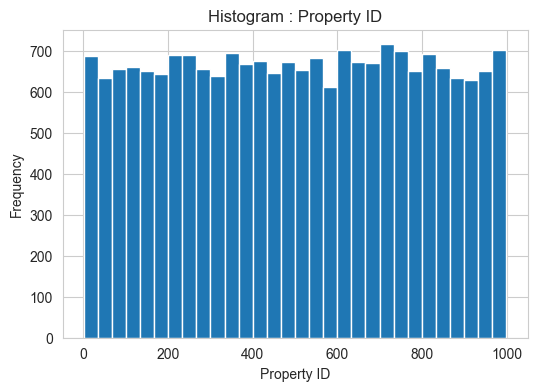

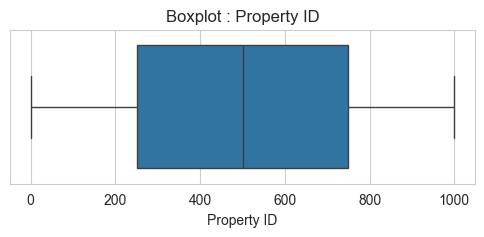

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2534.102
Median     : 2220.605
Std Dev    : 1408.509
Variance   : 1983898.322
Skewness   : 3.358
Kurtosis   : 30.483


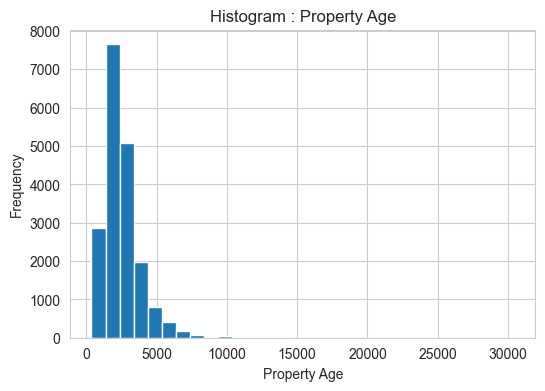

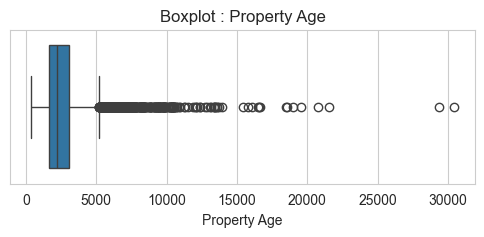

Outliers Detected : 822

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.472
Median     : 2.000
Std Dev    : 1.126
Variance   : 1.267
Skewness   : 0.034
Kurtosis   : -1.376


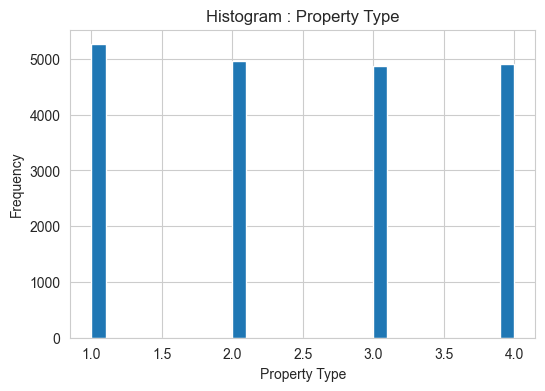

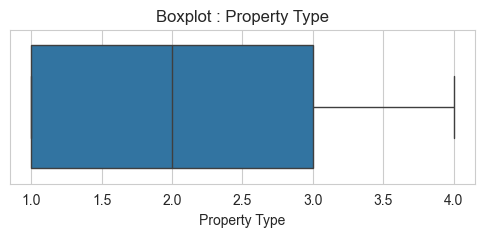

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : 0.853
Median     : 1.000
Std Dev    : 0.354
Variance   : 0.125
Skewness   : -1.999
Kurtosis   : 1.998


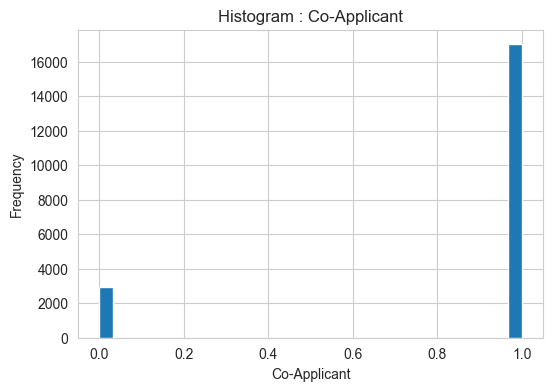

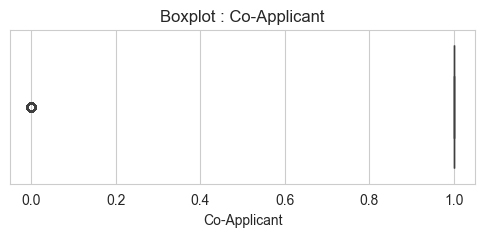

Outliers Detected : 2919

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 133466.497
Median     : 110871.825
Std Dev    : 93334.862
Variance   : 8711396458.667
Skewness   : 1.389
Kurtosis   : 2.496


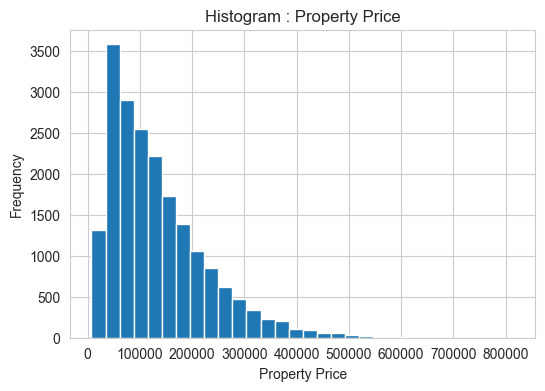

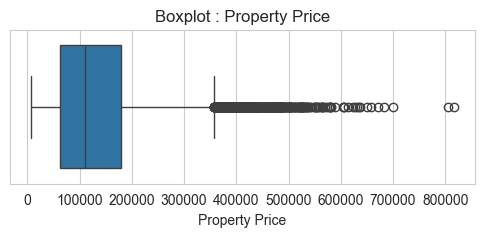

Outliers Detected : 606


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
F      10142
M       9827
NaN       31
Name: count, dtype: int64


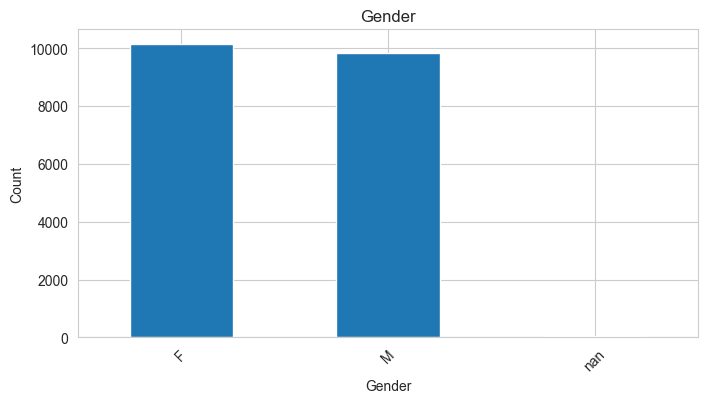


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     17501
High     1686
NaN       813
Name: count, dtype: int64


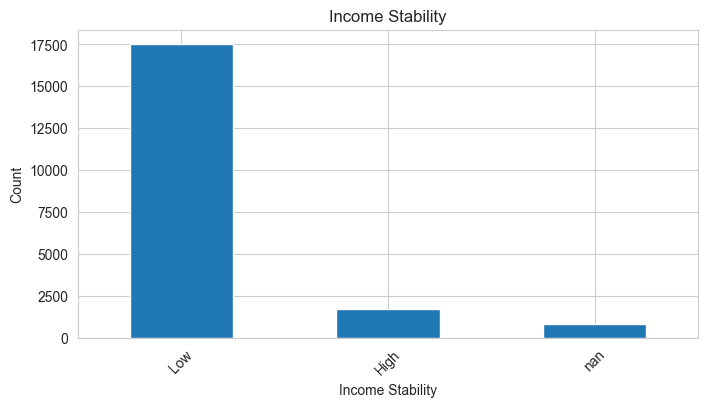


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 7
Profession
Working                 11405
Commercial associate     5247
Pensioner                1764
State servant            1577
Student                     4
Unemployed                  2
Maternity leave             1
Name: count, dtype: int64


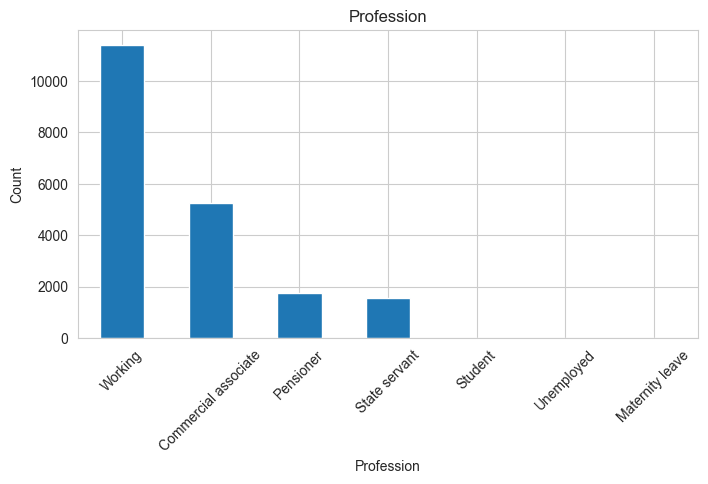


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
NaN                      4689
Laborers                 3743
Sales staff              2433
Core staff               2232
Managers                 1719
Drivers                  1057
Accountants               886
High skill tech staff     881
Medicine staff            598
Cooking staff             405
Security staff            377
Cleaning staff            230
Private service staff     201
Low-skill Laborers        141
Secretaries               119
Waiters/barmen staff      110
Realty agents              68
HR staff                   60
IT staff                   51
Name: count, dtype: int64


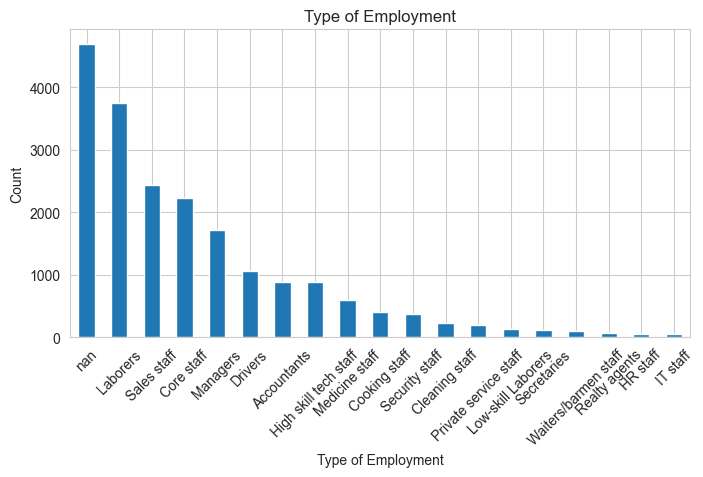


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    14463
Rural          3436
Urban          2101
Name: count, dtype: int64


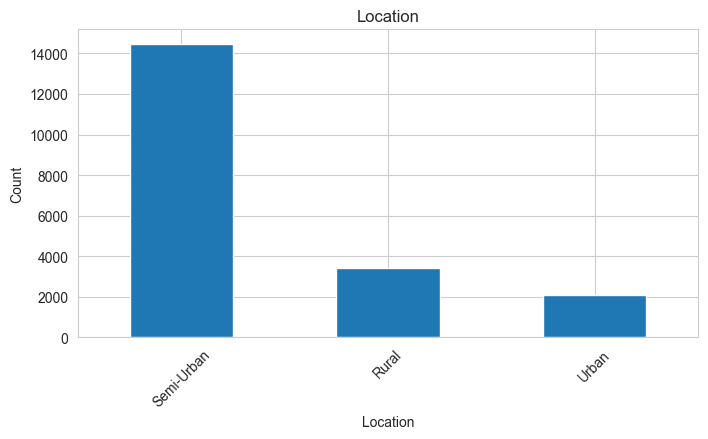


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    12816
Y     7184
Name: count, dtype: int64


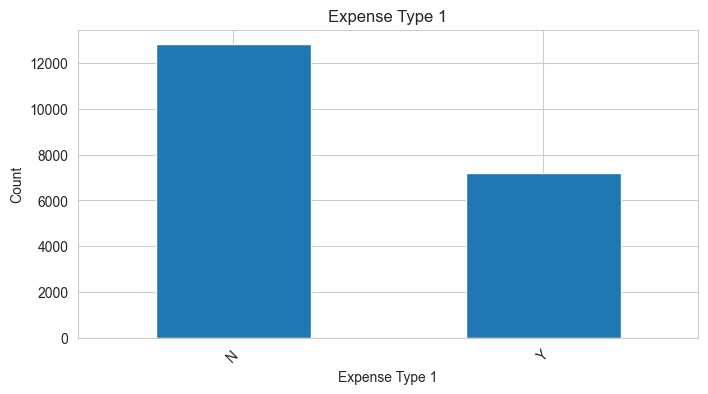


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    13383
N     6617
Name: count, dtype: int64


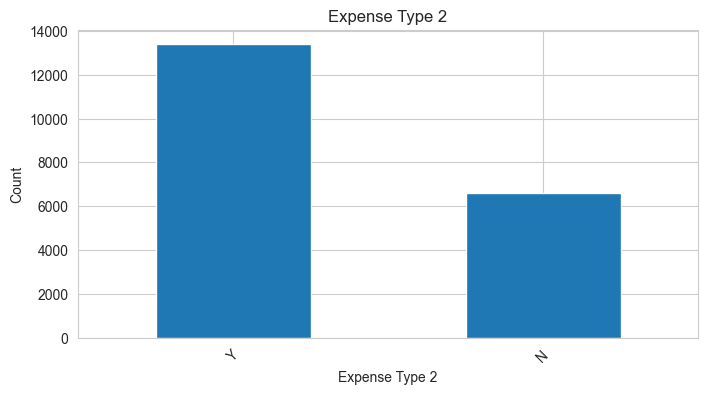


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         6418
Inactive       6376
Unpossessed    6130
NaN            1076
Name: count, dtype: int64


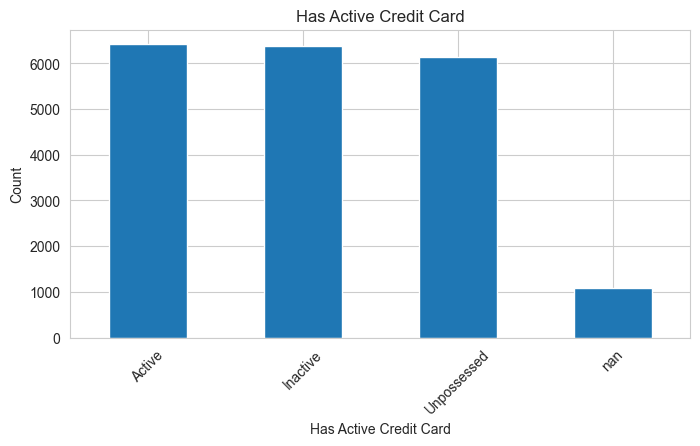


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    6839
Rural         6768
Urban         6233
NaN            160
Name: count, dtype: int64


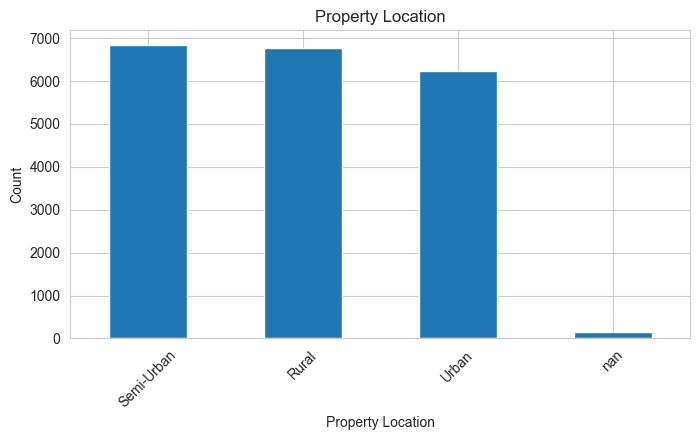



CORRELATION ANALYSIS


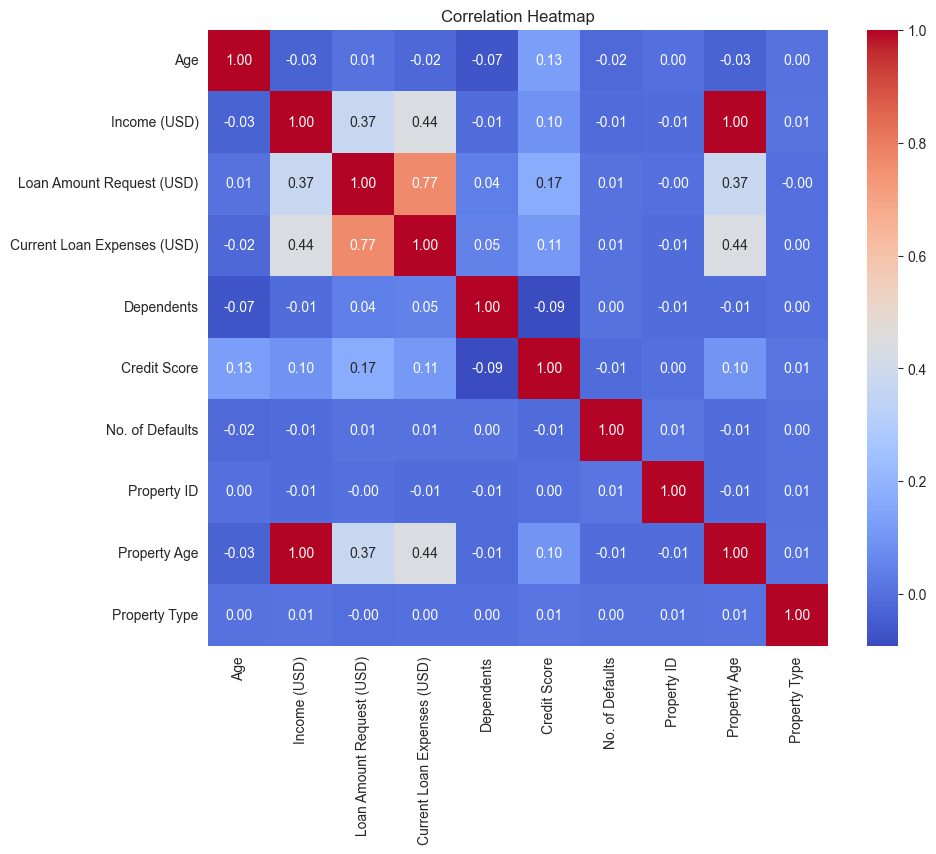


Highly Correlated Feature Pairs
Income (USD), Property Age = 1.0


TARGET ANALYSIS
No target provided as parameter!


FINAL EDA SUMMARY
Rows                     : 20000
Columns                  : 23
Numerical Columns        : 10
Categorical Columns      : 13
Duplicate Rows           : 0
Columns with Missing     : 10
Highly Correlated Pairs  : 1

EDA Completed Successfully.


In [6]:
tabular_eda(test, "regression")

## 5. Checking for Missing Value Placeholders
The test set uses '?' in place of missing values in some columns, so this is checked before cleaning.

In [7]:
test["Co-Applicant"].unique()

array(['1', '0', '?'], dtype=object)

In [8]:
for col in test.columns:
    if (test[col] == '?').any():
        print(col)

Co-Applicant
Property Price


In [9]:
for col in ['Co-Applicant','Property Price']:
    count = (test[col] == '?').sum()
    if count > 0:
        print(f"{col}: {count}")

Co-Applicant: 77
Property Price: 168


## 6. Data Cleaning
Fill the missing values in both the train and test sets.

In [10]:
# Data Cleaning

train['Gender']= train['Gender'].fillna(train['Gender'].mode()[0])
train['Income (USD)']= train['Income (USD)'].fillna(train['Income (USD)'].mode()[0])
train['Income Stability']= train['Income Stability'].fillna(train['Income Stability'].mode()[0])
train['Type of Employment']= train['Type of Employment'].fillna(train['Type of Employment'].mode()[0])
train['Current Loan Expenses (USD)']= train['Current Loan Expenses (USD)'].fillna(train['Current Loan Expenses (USD)'].mode()[0])
train['Dependents']= train['Dependents'].fillna(train['Dependents'].mode()[0])
train['Credit Score']= train['Credit Score'].fillna(train['Credit Score'].mode()[0])
train['Has Active Credit Card']= train['Has Active Credit Card'].fillna(train['Has Active Credit Card'].mode()[0])
train['Property Age']= train['Property Age'].fillna(train['Property Age'].mode()[0])
train['Property Location']= train['Property Location'].fillna(train['Property Location'].mode()[0])
train['Loan Sanction Amount (USD)']= train['Loan Sanction Amount (USD)'].fillna(train['Loan Sanction Amount (USD)'].mode()[0])

In [11]:

test['Gender']= test['Gender'].fillna(test['Gender'].mode()[0])
test['Income (USD)']= test['Income (USD)'].fillna(test['Income (USD)'].mode()[0])
test['Income Stability']= test['Income Stability'].fillna(test['Income Stability'].mode()[0])
test['Type of Employment']= test['Type of Employment'].fillna(test['Type of Employment'].mode()[0])
test['Current Loan Expenses (USD)']= test['Current Loan Expenses (USD)'].fillna(test['Current Loan Expenses (USD)'].mode()[0])
test['Dependents']= test['Dependents'].fillna(test['Dependents'].mode()[0])
test['Credit Score']= test['Credit Score'].fillna(test['Credit Score'].mode()[0])
test['Has Active Credit Card']= test['Has Active Credit Card'].fillna(test['Has Active Credit Card'].mode()[0])
test['Property Age']= test['Property Age'].fillna(test['Property Age'].mode()[0])
test['Property Location']= test['Property Location'].fillna(test['Property Location'].mode()[0])
test['Co-Applicant'] = test['Co-Applicant'].replace('?', np.nan)
test['Property Price'] = test['Property Price'].replace('?', np.nan)
test['Co-Applicant']= test['Co-Applicant'].fillna(test['Co-Applicant'].mode()[0])
test['Property Price']= test['Property Price'].fillna(test['Property Price'].mode()[0])

## 7. Exploratory Data Analysis (After Cleaning)

DATASET OVERVIEW

Rows                : 30000
Columns             : 24

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price
Loan Sanction Amount (USD)

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  30000 non-null  object 
 1   Name                         30000 non-null  object 
 2   Gender                       30000 no

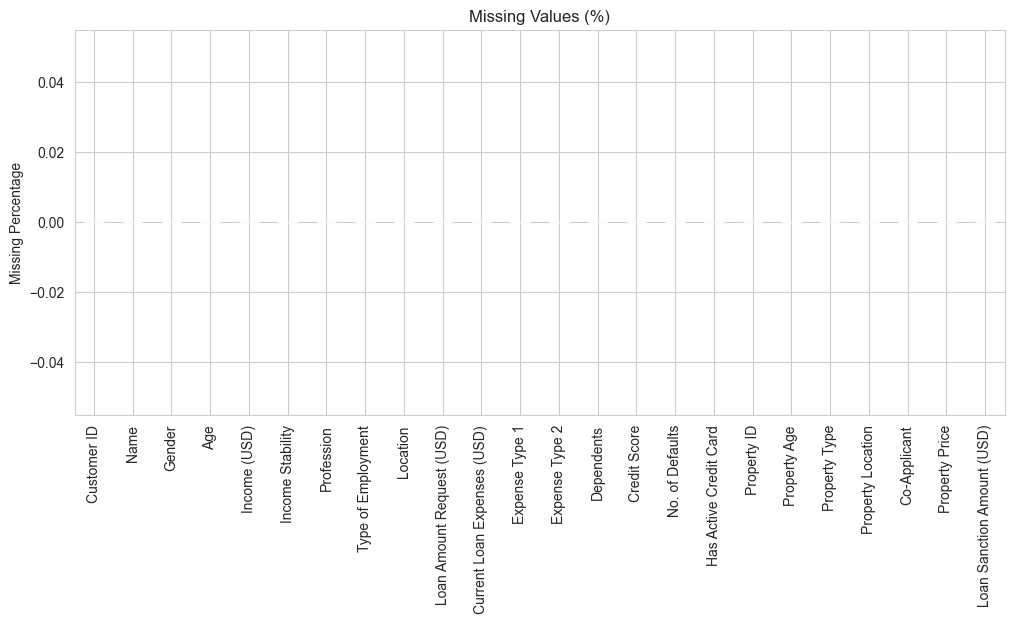



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


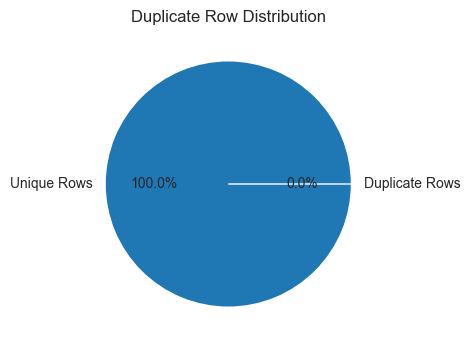



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 40.092
Median     : 40.000
Std Dev    : 16.045
Variance   : 257.446
Skewness   : 0.046
Kurtosis   : -1.382


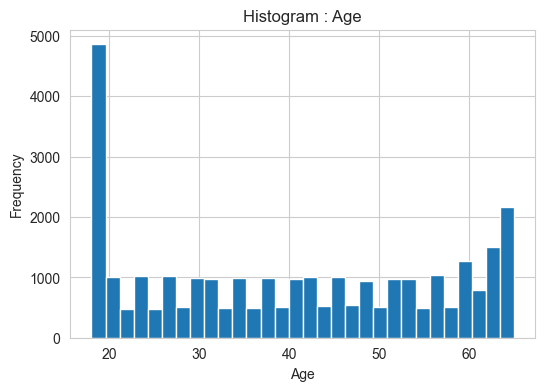

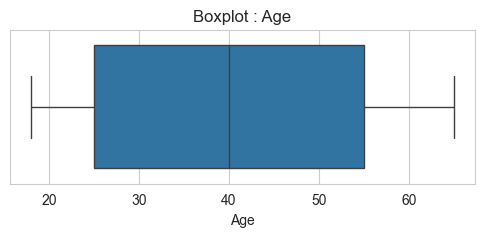

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2474.663
Median     : 2002.225
Std Dev    : 10374.713
Variance   : 107634670.101
Skewness   : 167.016
Kurtosis   : 28564.023


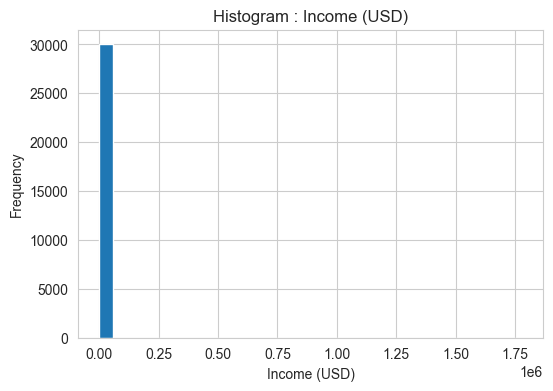

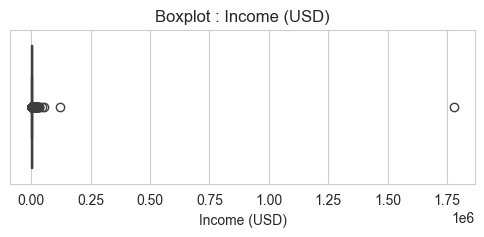

Outliers Detected : 1641

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88826.334
Median     : 75128.075
Std Dev    : 59536.950
Variance   : 3544648368.253
Skewness   : 1.260
Kurtosis   : 2.103


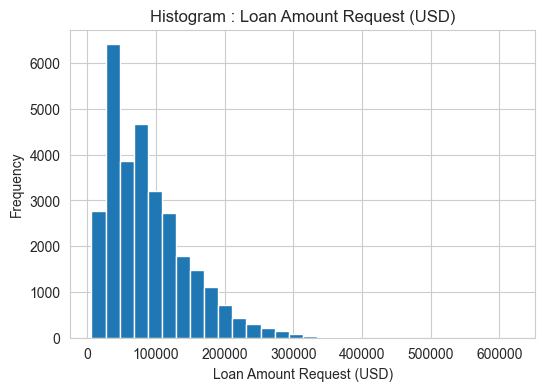

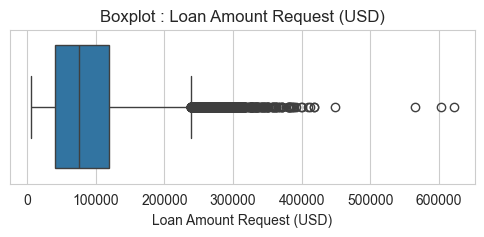

Outliers Detected : 752

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 392.911
Median     : 373.845
Std Dev    : 263.938
Variance   : 69663.236
Skewness   : -0.730
Kurtosis   : 11.194


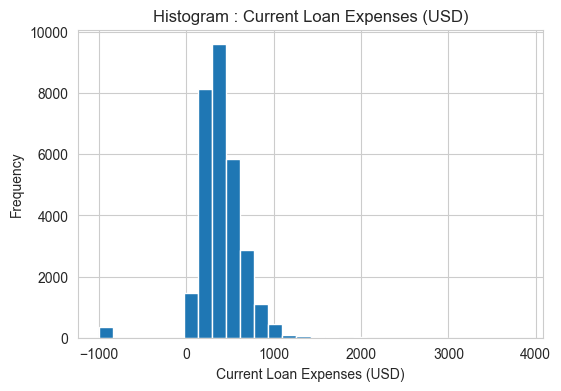

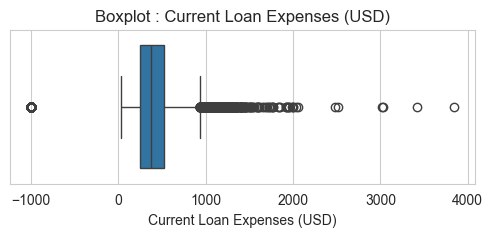

Outliers Detected : 1028

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.232
Median     : 2.000
Std Dev    : 0.913
Variance   : 0.834
Skewness   : 0.900
Kurtosis   : 1.821


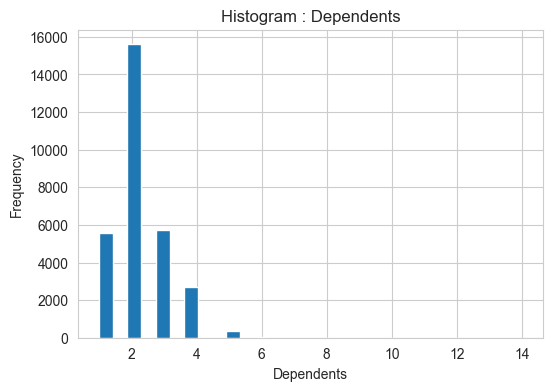

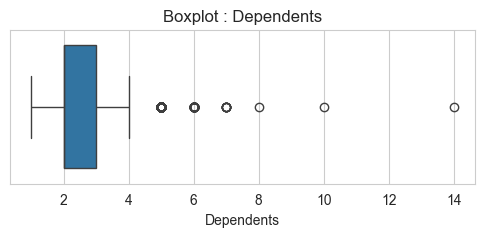

Outliers Detected : 432

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 742.887
Median     : 746.975
Std Dev    : 71.146
Variance   : 5061.691
Skewness   : -0.123
Kurtosis   : -0.961


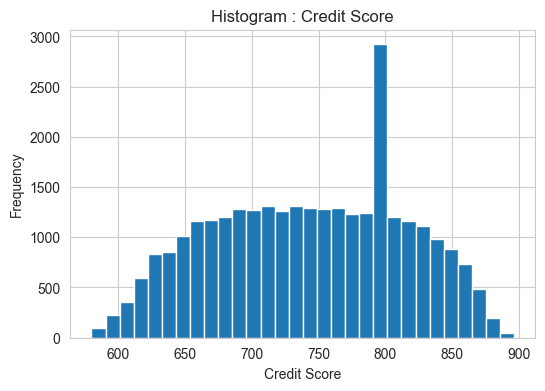

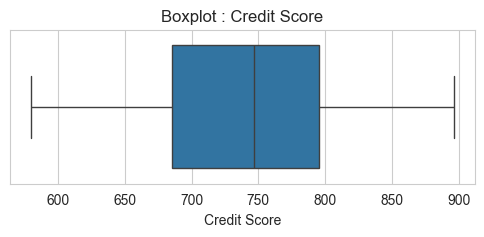

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.194
Median     : 0.000
Std Dev    : 0.395
Variance   : 0.156
Skewness   : 1.548
Kurtosis   : 0.397


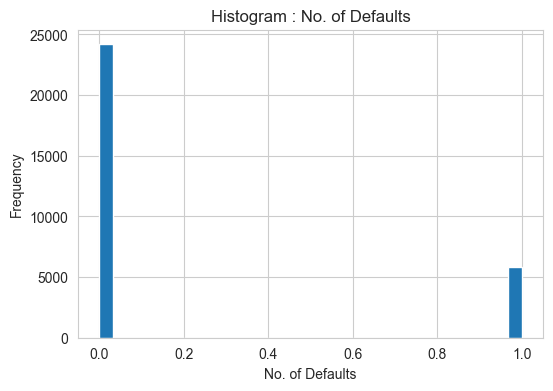

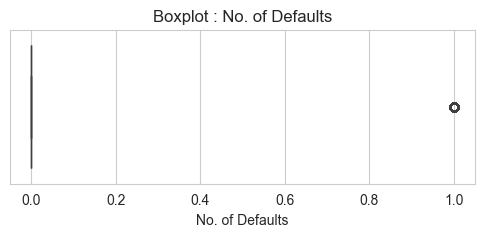

Outliers Detected : 5818

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.935
Median     : 504.000
Std Dev    : 288.158
Variance   : 83035.082
Skewness   : -0.011
Kurtosis   : -1.203


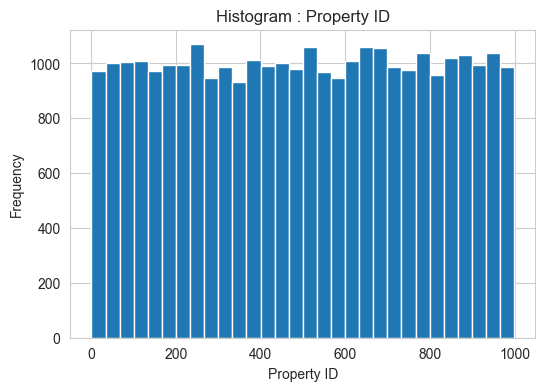

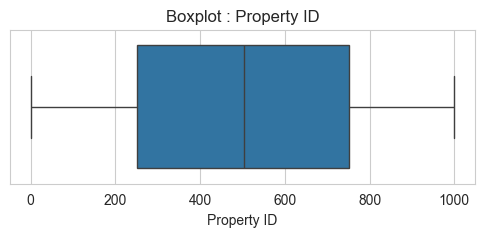

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2465.785
Median     : 1988.570
Std Dev    : 10373.906
Variance   : 107617924.833
Skewness   : 167.058
Kurtosis   : 28573.486


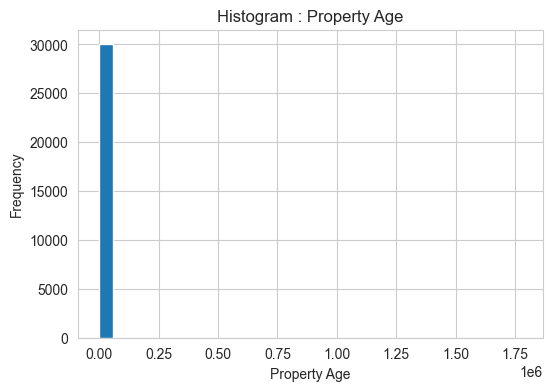

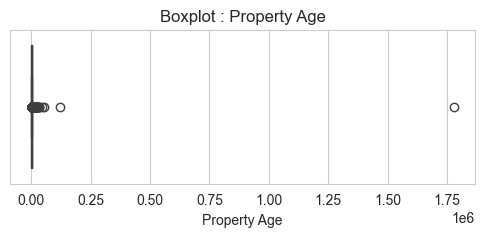

Outliers Detected : 1673

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.460
Median     : 2.000
Std Dev    : 1.119
Variance   : 1.251
Skewness   : 0.051
Kurtosis   : -1.359


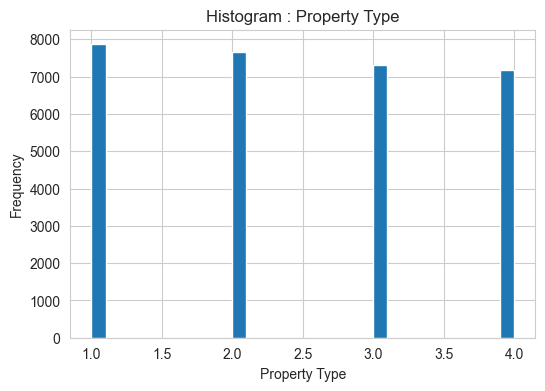

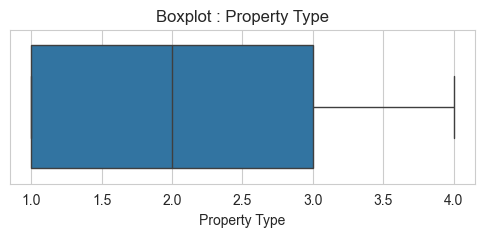

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : -4.744
Median     : 1.000
Std Dev    : 74.615
Variance   : 5567.337
Skewness   : -13.251
Kurtosis   : 173.598


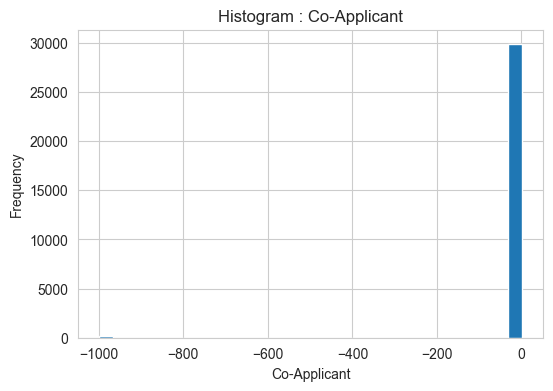

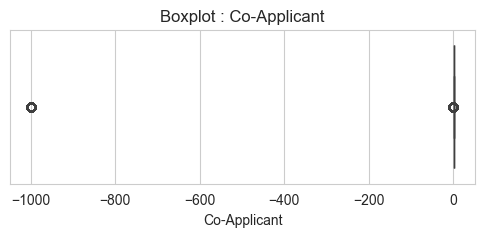

Outliers Detected : 4484

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 131759.680
Median     : 109993.610
Std Dev    : 93549.548
Variance   : 8751517950.503
Skewness   : 1.417
Kurtosis   : 3.149


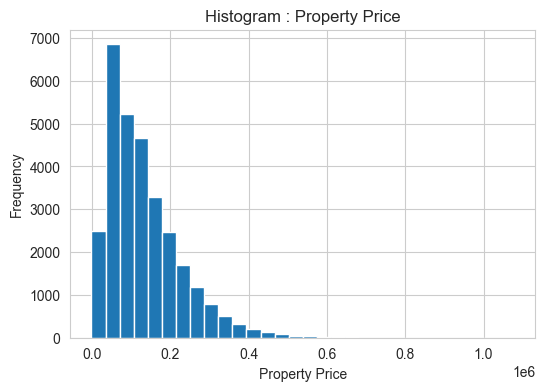

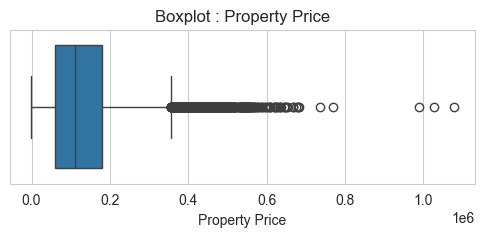

Outliers Detected : 863

--------------------------------------------------------------------------------
Column : Loan Sanction Amount (USD)
--------------------------------------------------------------------------------
Mean       : 47109.316
Median     : 34401.320
Std Dev    : 48211.680
Variance   : 2324366045.314
Skewness   : 1.239
Kurtosis   : 1.775


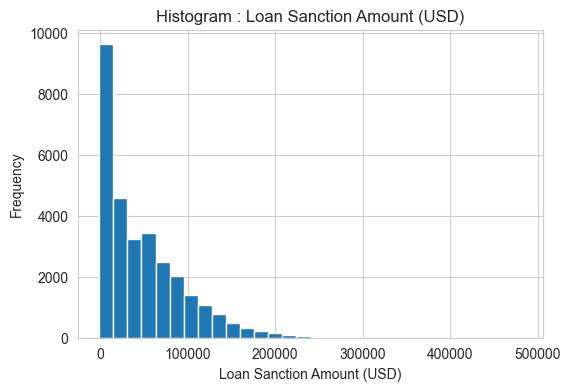

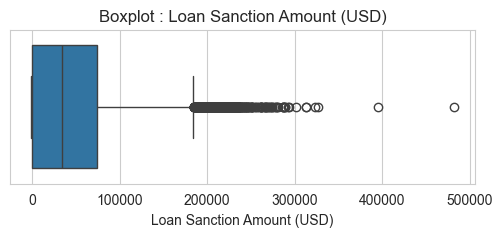

Outliers Detected : 453


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 30000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
M    15106
F    14894
Name: count, dtype: int64


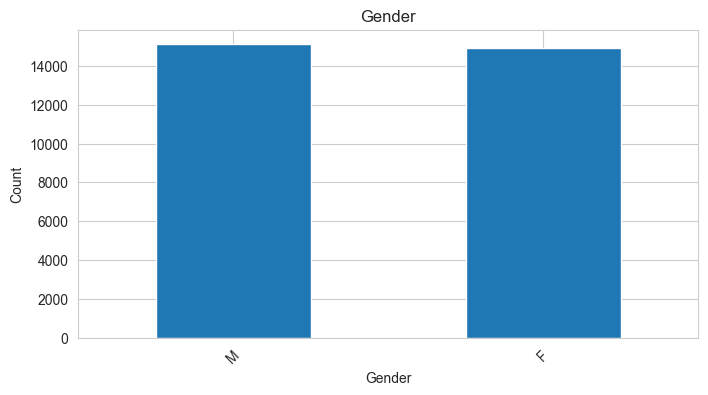


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     27434
High     2566
Name: count, dtype: int64


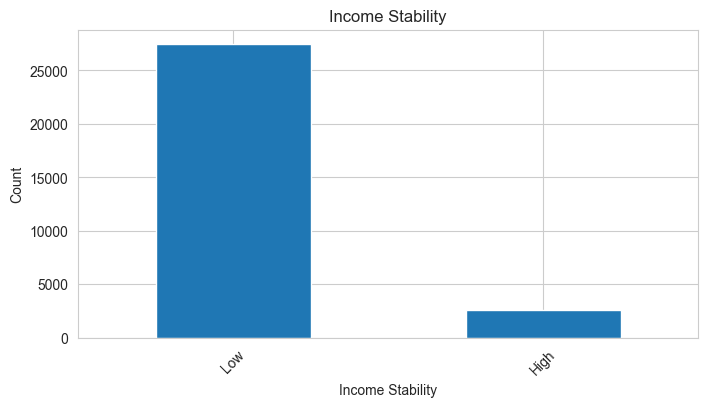


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 8
Profession
Working                 16926
Commercial associate     7962
Pensioner                2740
State servant            2366
Unemployed                  2
Businessman                 2
Student                     1
Maternity leave             1
Name: count, dtype: int64


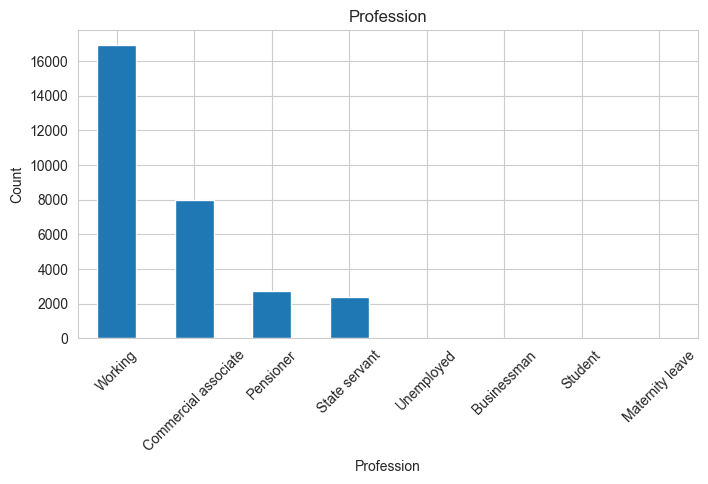


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
Laborers                 12848
Sales staff               3736
Core staff                3230
Managers                  2495
Drivers                   1606
Accountants               1379
High skill tech staff     1307
Medicine staff             864
Security staff             579
Cooking staff              566
Private service staff      342
Cleaning staff             341
Low-skill Laborers         162
Secretaries                161
Waiters/barmen staff       149
Realty agents               86
IT staff                    77
HR staff                    72
Name: count, dtype: int64


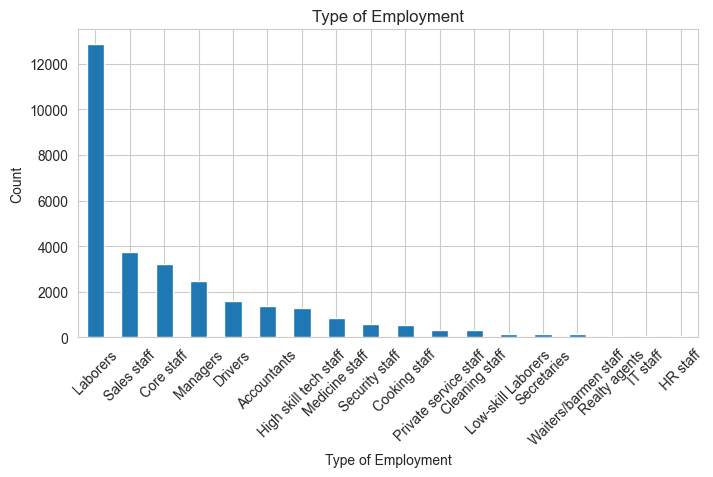


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    21563
Rural          5338
Urban          3099
Name: count, dtype: int64


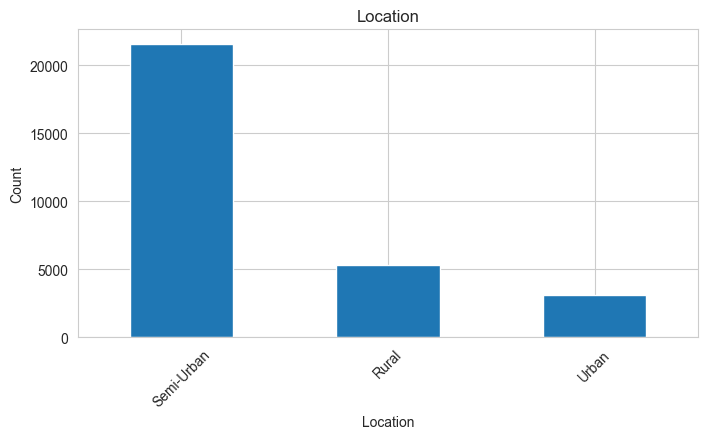


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    19214
Y    10786
Name: count, dtype: int64


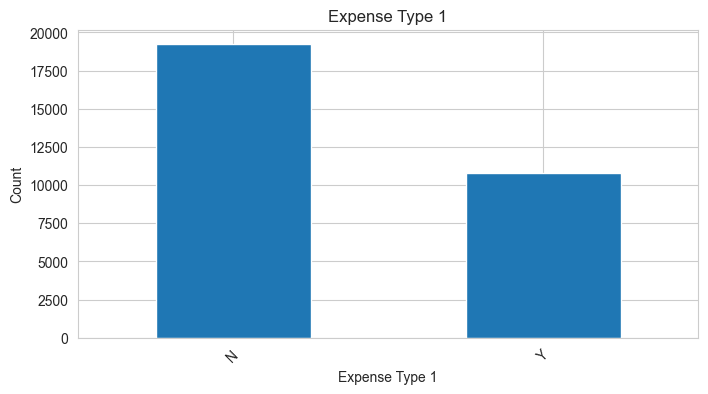


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    20180
N     9820
Name: count, dtype: int64


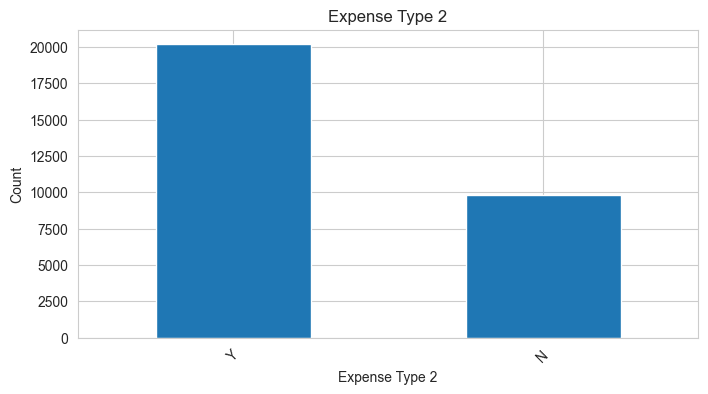


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         11337
Inactive        9466
Unpossessed     9197
Name: count, dtype: int64


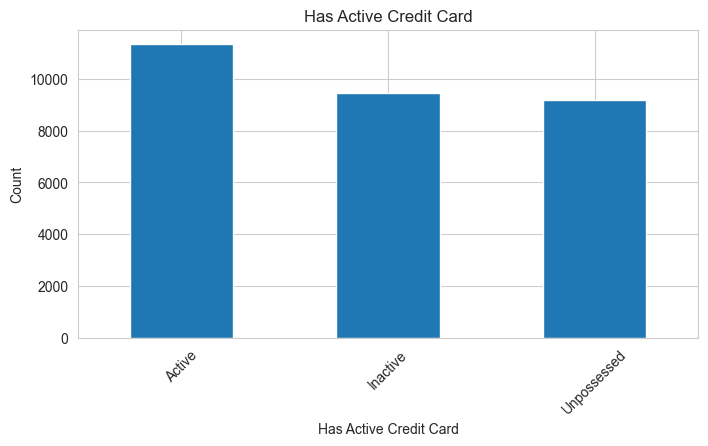


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    10743
Rural         10041
Urban          9216
Name: count, dtype: int64


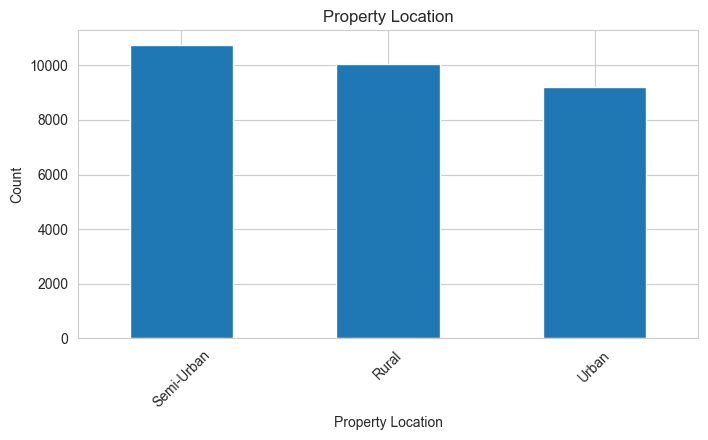



CORRELATION ANALYSIS


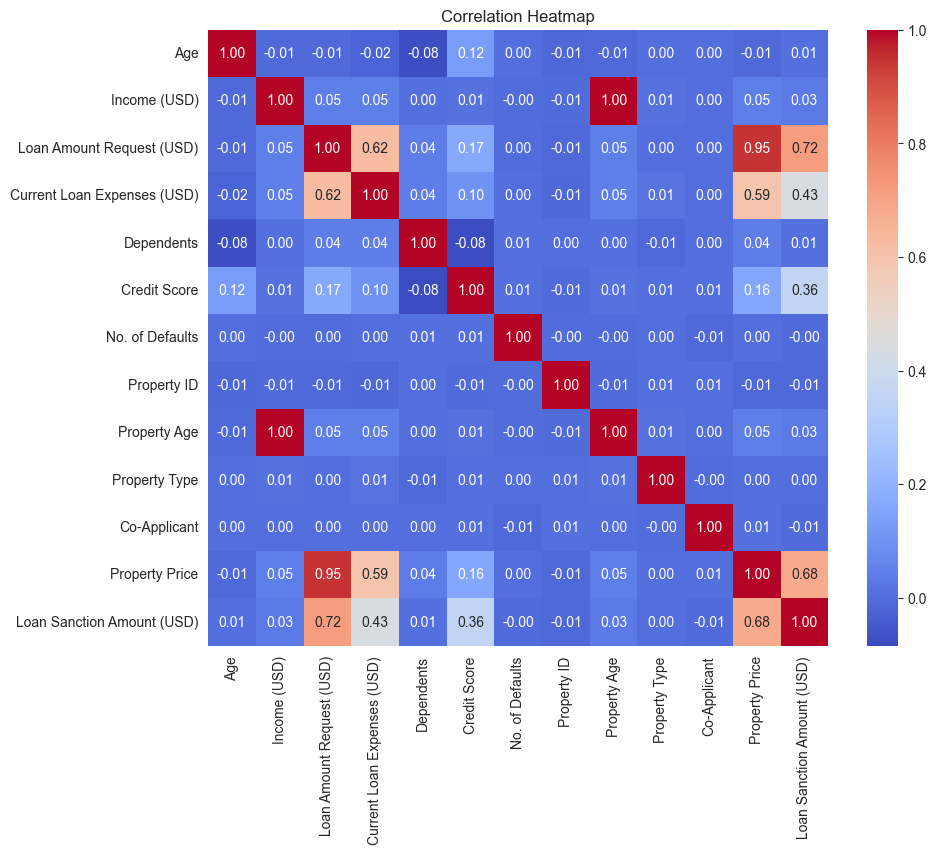


Highly Correlated Feature Pairs
Income (USD), Property Age = 0.9998514792767736
Loan Amount Request (USD), Property Price = 0.9483497026229606


TARGET ANALYSIS
count     30000.000000
mean      47109.316330
std       48211.679553
min        -999.000000
25%           0.000000
50%       34401.320000
75%       73763.532500
max      481907.320000
Name: Loan Sanction Amount (USD), dtype: float64


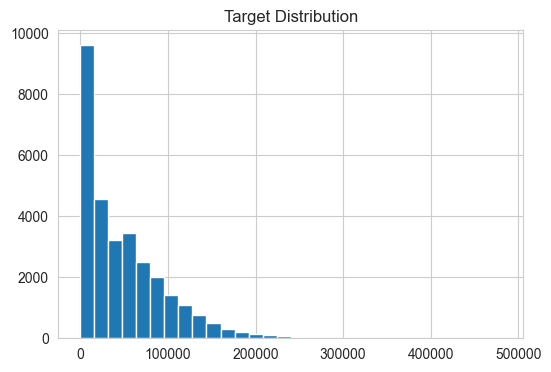



FINAL EDA SUMMARY
Rows                     : 30000
Columns                  : 24
Numerical Columns        : 13
Categorical Columns      : 11
Duplicate Rows           : 0
Columns with Missing     : 0
Highly Correlated Pairs  : 2

EDA Completed Successfully.


In [12]:
tabular_eda(train, "regression","Loan Sanction Amount (USD)")

DATASET OVERVIEW

Rows                : 20000
Columns             : 23

Column Names
--------------------------------------------------------------------------------
Customer ID
Name
Gender
Age
Income (USD)
Income Stability
Profession
Type of Employment
Location
Loan Amount Request (USD)
Current Loan Expenses (USD)
Expense Type 1
Expense Type 2
Dependents
Credit Score
No. of Defaults
Has Active Credit Card
Property ID
Property Age
Property Type
Property Location
Co-Applicant
Property Price

Dataset Info
--------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer ID                  20000 non-null  object 
 1   Name                         20000 non-null  object 
 2   Gender                       20000 non-null  object 
 3   Age   

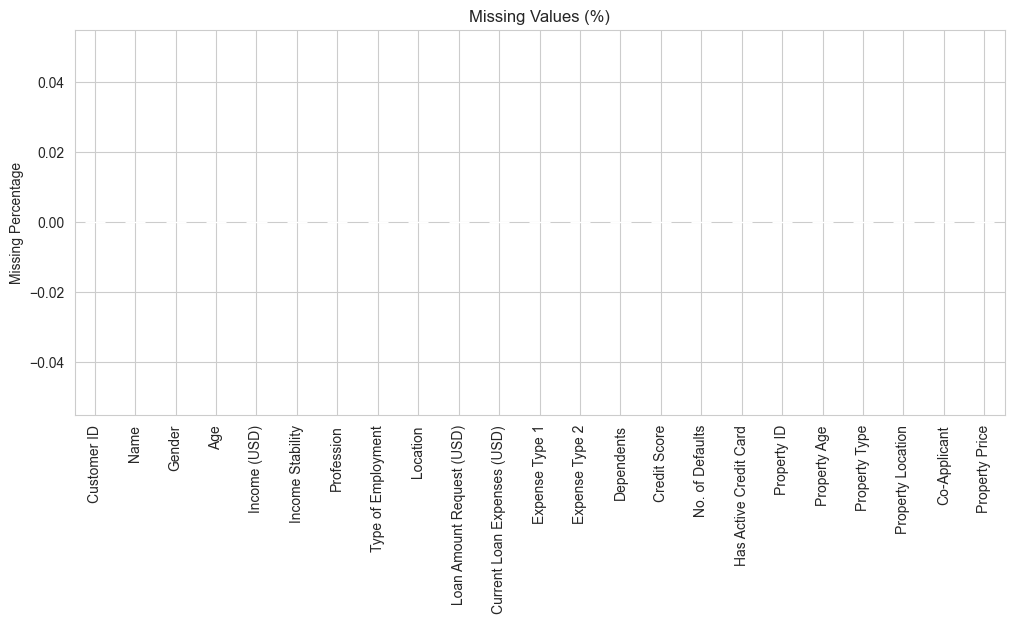



DUPLICATE ANALYSIS
Duplicate Rows       : 0
Duplicate Percentage : 0.00%


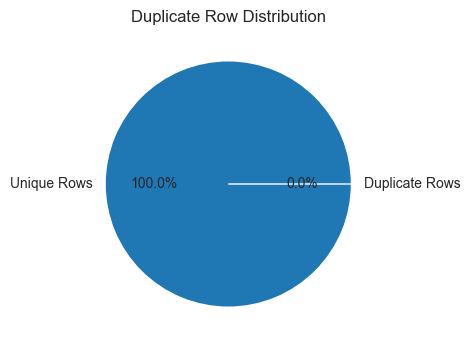



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Age
--------------------------------------------------------------------------------
Mean       : 39.941
Median     : 40.000
Std Dev    : 16.098
Variance   : 259.133
Skewness   : 0.055
Kurtosis   : -1.387


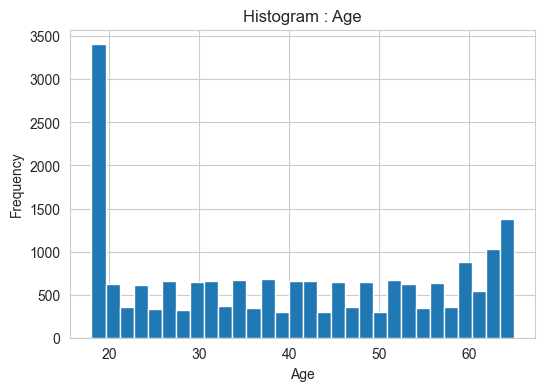

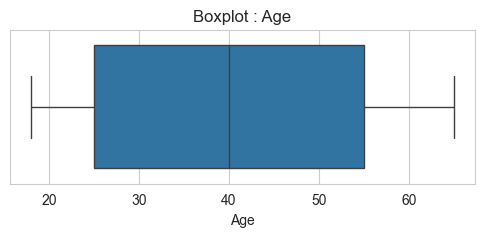

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Income (USD)
--------------------------------------------------------------------------------
Mean       : 2490.656
Median     : 2162.425
Std Dev    : 1408.805
Variance   : 1984732.598
Skewness   : 3.405
Kurtosis   : 30.905


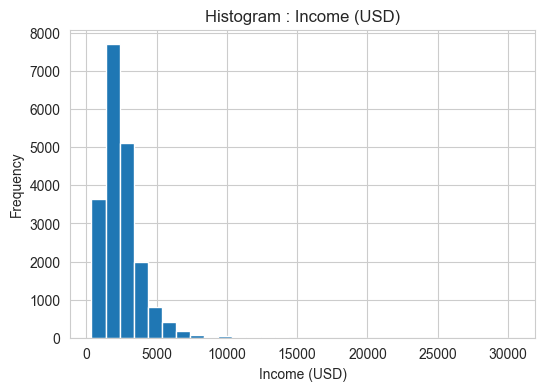

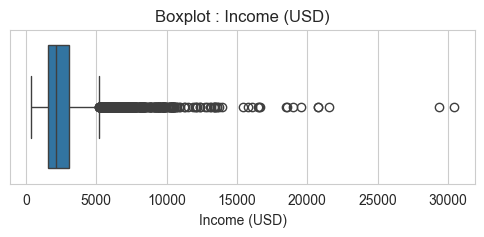

Outliers Detected : 830

--------------------------------------------------------------------------------
Column : Loan Amount Request (USD)
--------------------------------------------------------------------------------
Mean       : 88859.077
Median     : 74565.990
Std Dev    : 60007.334
Variance   : 3600880094.522
Skewness   : 1.278
Kurtosis   : 1.971


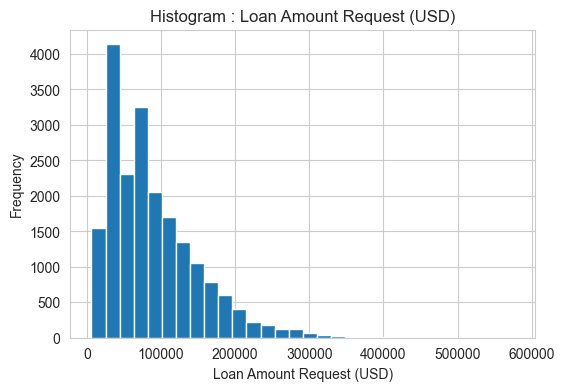

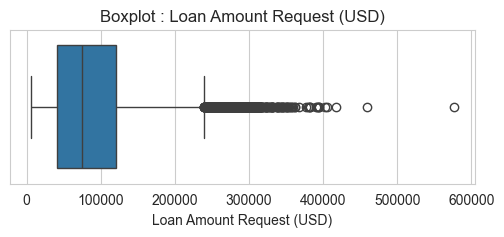

Outliers Detected : 511

--------------------------------------------------------------------------------
Column : Current Loan Expenses (USD)
--------------------------------------------------------------------------------
Mean       : 407.325
Median     : 373.310
Std Dev    : 216.117
Variance   : 46706.707
Skewness   : 1.374
Kurtosis   : 5.415


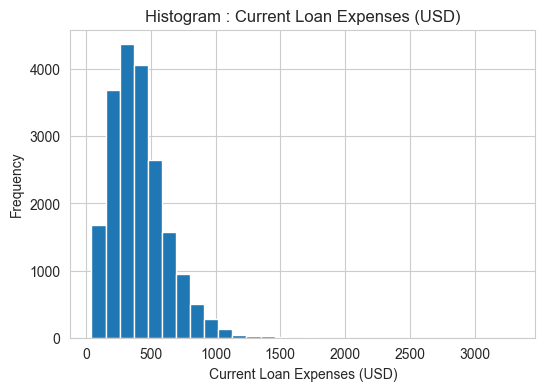

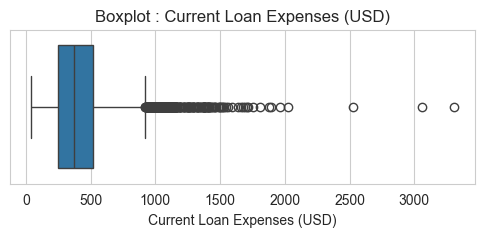

Outliers Detected : 481

--------------------------------------------------------------------------------
Column : Dependents
--------------------------------------------------------------------------------
Mean       : 2.237
Median     : 2.000
Std Dev    : 0.927
Variance   : 0.860
Skewness   : 0.872
Kurtosis   : 1.757


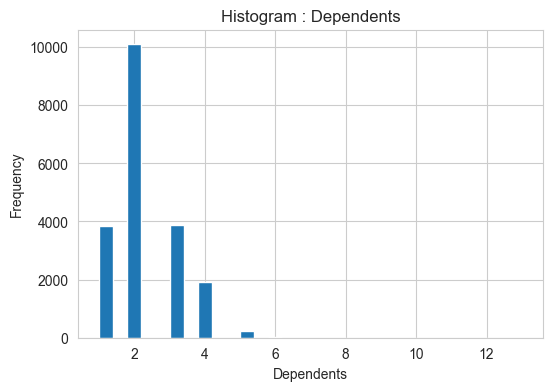

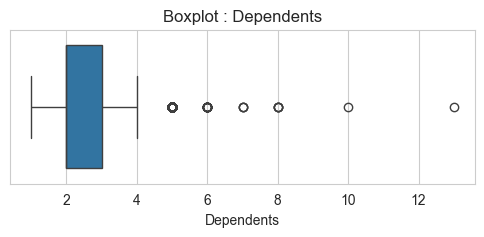

Outliers Detected : 275

--------------------------------------------------------------------------------
Column : Credit Score
--------------------------------------------------------------------------------
Mean       : 735.713
Median     : 734.685
Std Dev    : 72.790
Variance   : 5298.361
Skewness   : 0.060
Kurtosis   : -1.042


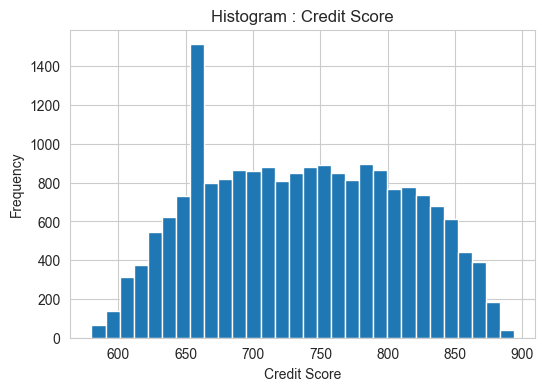

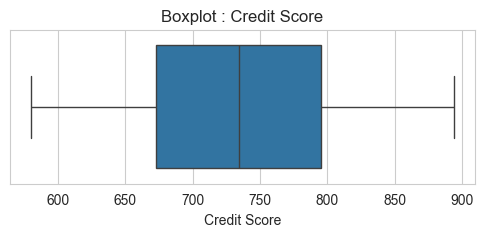

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : No. of Defaults
--------------------------------------------------------------------------------
Mean       : 0.190
Median     : 0.000
Std Dev    : 0.392
Variance   : 0.154
Skewness   : 1.585
Kurtosis   : 0.511


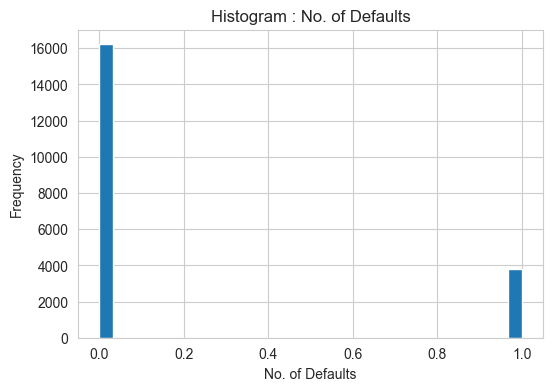

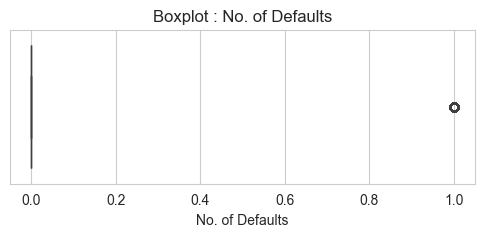

Outliers Detected : 3790

--------------------------------------------------------------------------------
Column : Property ID
--------------------------------------------------------------------------------
Mean       : 501.024
Median     : 501.000
Std Dev    : 287.538
Variance   : 82677.941
Skewness   : -0.007
Kurtosis   : -1.194


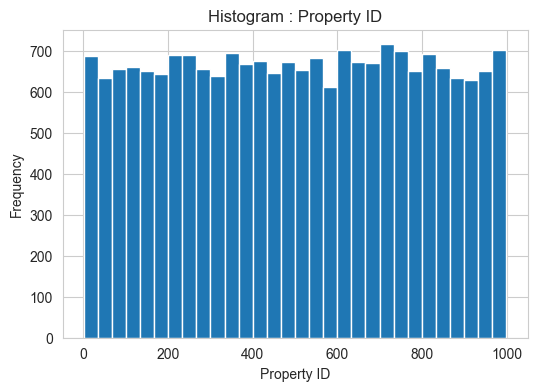

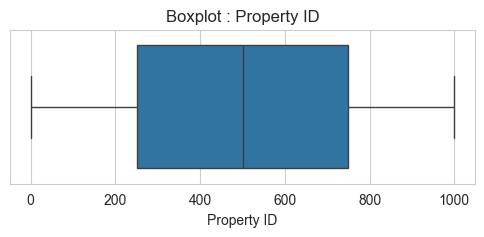

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Property Age
--------------------------------------------------------------------------------
Mean       : 2479.118
Median     : 2146.280
Std Dev    : 1400.064
Variance   : 1960178.411
Skewness   : 3.354
Kurtosis   : 30.313


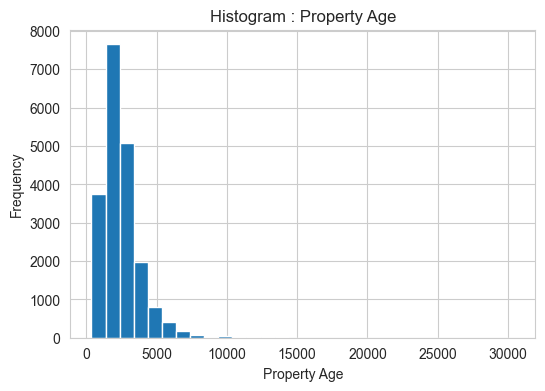

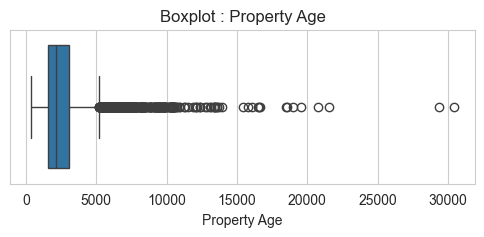

Outliers Detected : 821

--------------------------------------------------------------------------------
Column : Property Type
--------------------------------------------------------------------------------
Mean       : 2.472
Median     : 2.000
Std Dev    : 1.126
Variance   : 1.267
Skewness   : 0.034
Kurtosis   : -1.376


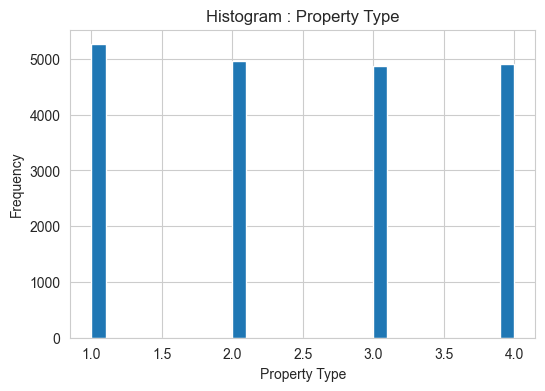

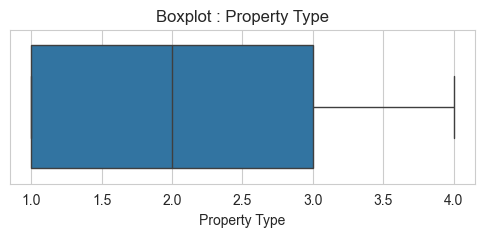

Outliers Detected : 0

--------------------------------------------------------------------------------
Column : Co-Applicant
--------------------------------------------------------------------------------
Mean       : 0.854
Median     : 1.000
Std Dev    : 0.353
Variance   : 0.125
Skewness   : -2.006
Kurtosis   : 2.023


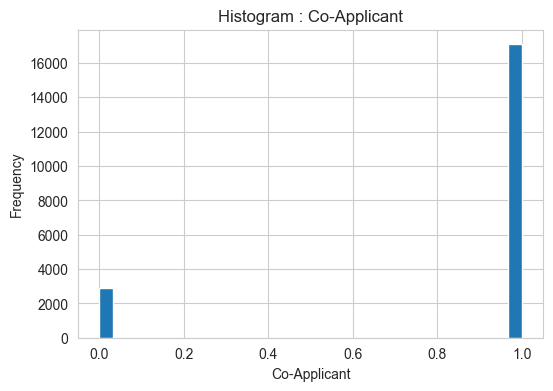

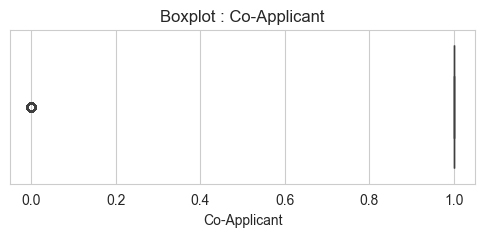

Outliers Detected : 2919

--------------------------------------------------------------------------------
Column : Property Price
--------------------------------------------------------------------------------
Mean       : 133193.883
Median     : 110060.590
Std Dev    : 92989.196
Variance   : 8646990633.434
Skewness   : 1.401
Kurtosis   : 2.547


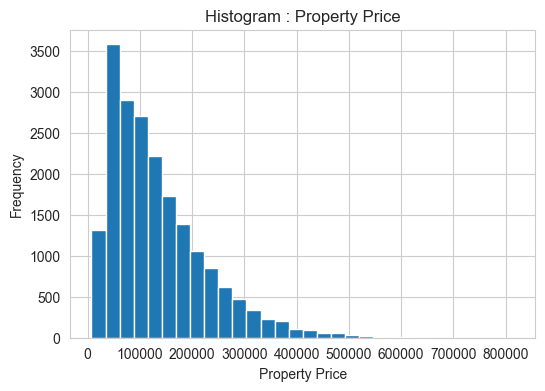

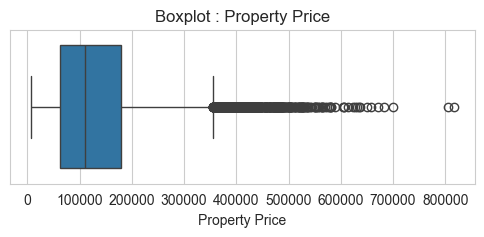

Outliers Detected : 628


CATEGORICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : Customer ID
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Name
--------------------------------------------------------------------------------
Unique Categories : 20000

--------------------------------------------------------------------------------
Column : Gender
--------------------------------------------------------------------------------
Unique Categories : 2
Gender
F    10173
M     9827
Name: count, dtype: int64


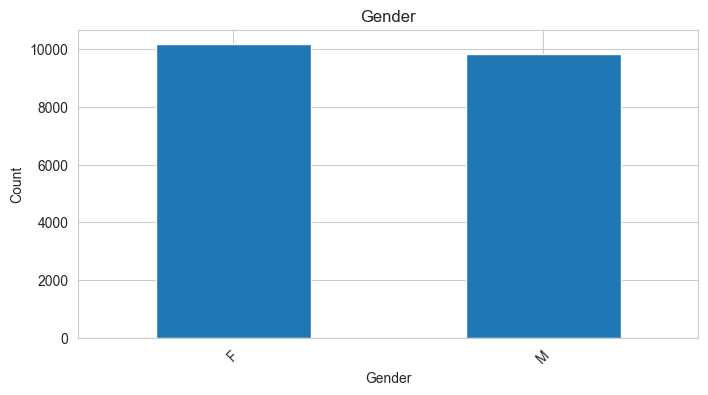


--------------------------------------------------------------------------------
Column : Income Stability
--------------------------------------------------------------------------------
Unique Categories : 2
Income Stability
Low     18314
High     1686
Name: count, dtype: int64


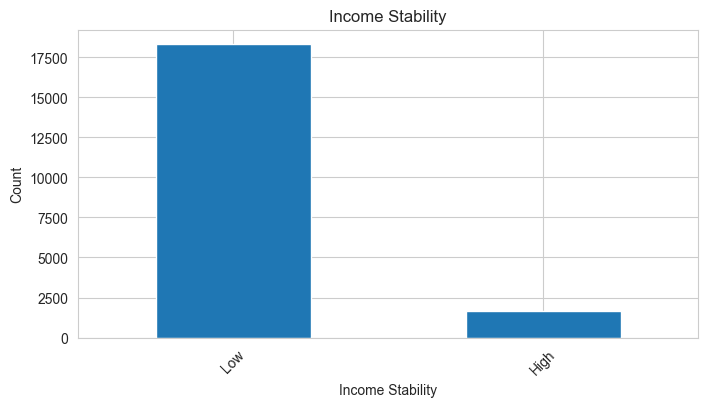


--------------------------------------------------------------------------------
Column : Profession
--------------------------------------------------------------------------------
Unique Categories : 7
Profession
Working                 11405
Commercial associate     5247
Pensioner                1764
State servant            1577
Student                     4
Unemployed                  2
Maternity leave             1
Name: count, dtype: int64


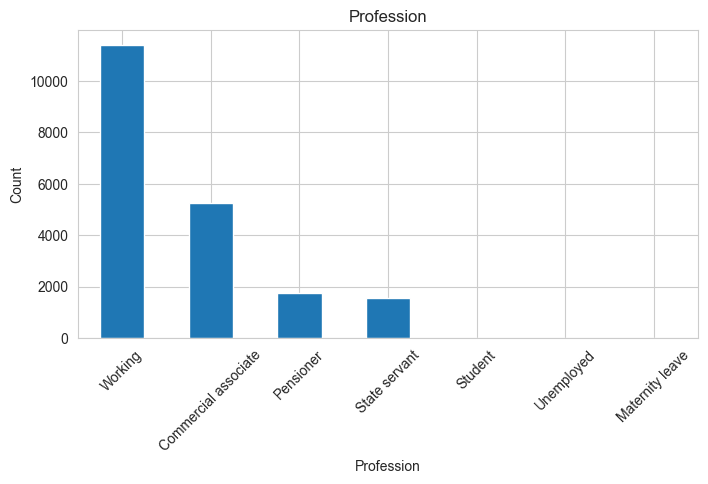


--------------------------------------------------------------------------------
Column : Type of Employment
--------------------------------------------------------------------------------
Unique Categories : 18
Type of Employment
Laborers                 8432
Sales staff              2433
Core staff               2232
Managers                 1719
Drivers                  1057
Accountants               886
High skill tech staff     881
Medicine staff            598
Cooking staff             405
Security staff            377
Cleaning staff            230
Private service staff     201
Low-skill Laborers        141
Secretaries               119
Waiters/barmen staff      110
Realty agents              68
HR staff                   60
IT staff                   51
Name: count, dtype: int64


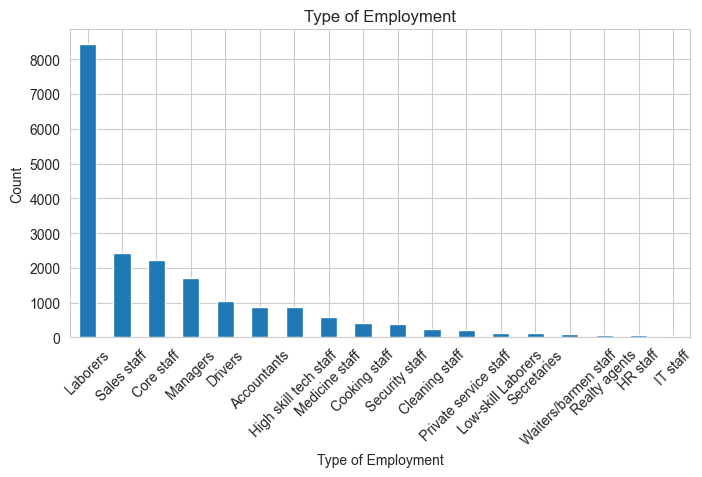


--------------------------------------------------------------------------------
Column : Location
--------------------------------------------------------------------------------
Unique Categories : 3
Location
Semi-Urban    14463
Rural          3436
Urban          2101
Name: count, dtype: int64


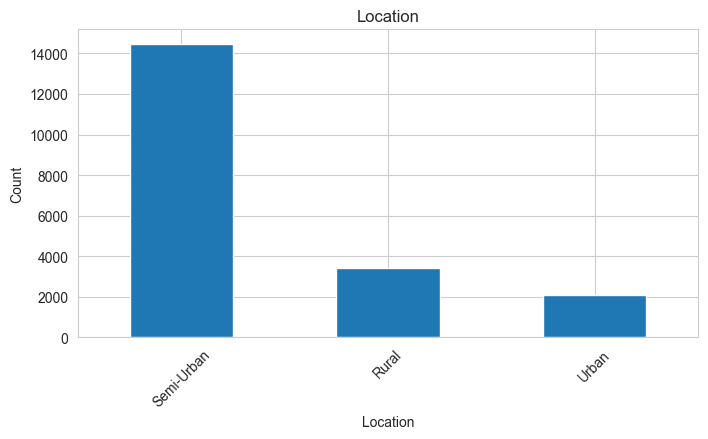


--------------------------------------------------------------------------------
Column : Expense Type 1
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 1
N    12816
Y     7184
Name: count, dtype: int64


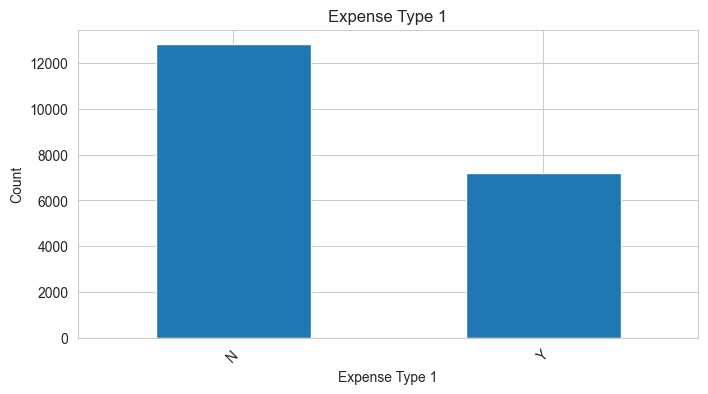


--------------------------------------------------------------------------------
Column : Expense Type 2
--------------------------------------------------------------------------------
Unique Categories : 2
Expense Type 2
Y    13383
N     6617
Name: count, dtype: int64


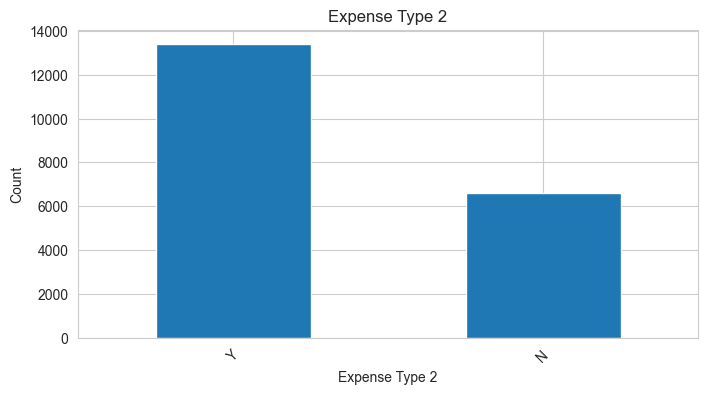


--------------------------------------------------------------------------------
Column : Has Active Credit Card
--------------------------------------------------------------------------------
Unique Categories : 3
Has Active Credit Card
Active         7494
Inactive       6376
Unpossessed    6130
Name: count, dtype: int64


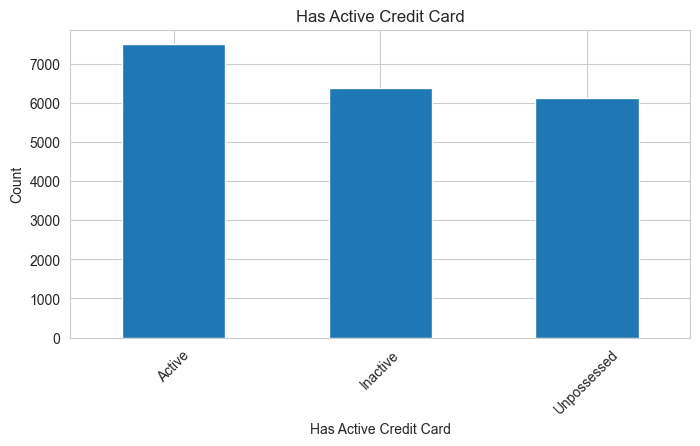


--------------------------------------------------------------------------------
Column : Property Location
--------------------------------------------------------------------------------
Unique Categories : 3
Property Location
Semi-Urban    6999
Rural         6768
Urban         6233
Name: count, dtype: int64


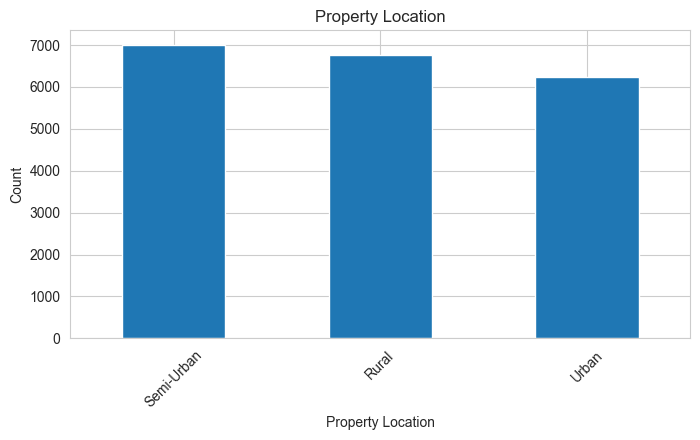



CORRELATION ANALYSIS


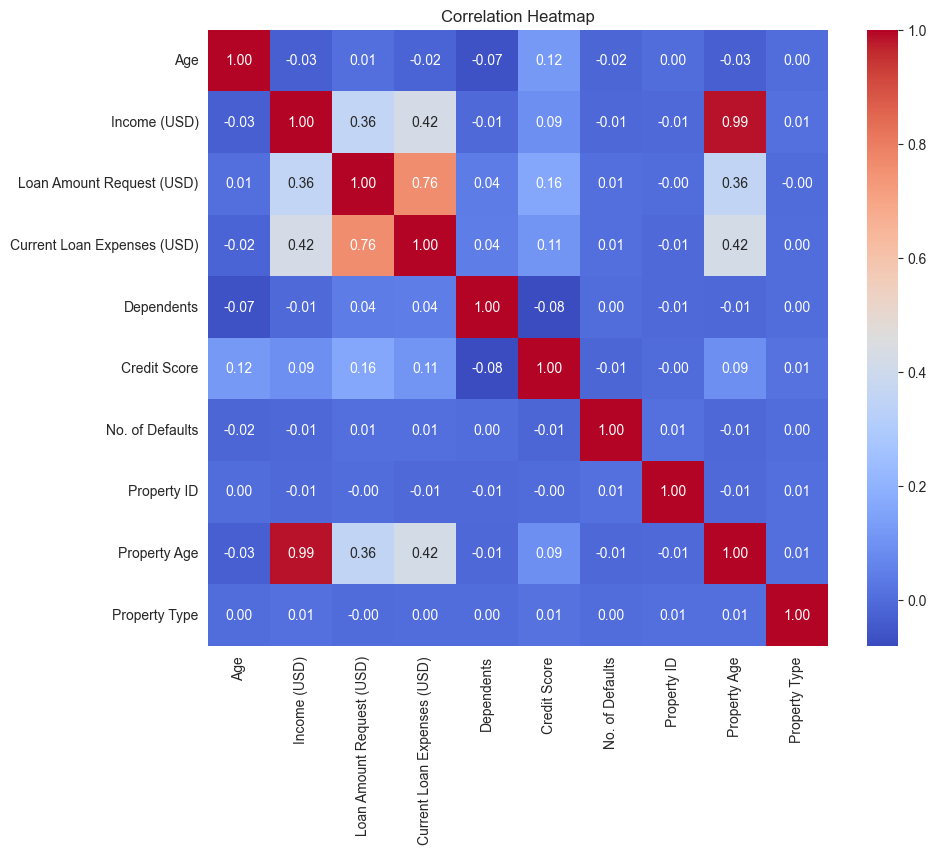


Highly Correlated Feature Pairs
Income (USD), Property Age = 0.9869046131097996


TARGET ANALYSIS
No target provided as parameter!


FINAL EDA SUMMARY
Rows                     : 20000
Columns                  : 23
Numerical Columns        : 10
Categorical Columns      : 13
Duplicate Rows           : 0
Columns with Missing     : 0
Highly Correlated Pairs  : 1

EDA Completed Successfully.


In [13]:
tabular_eda(test, "regression")

## 8. Data Preprocessing
Encode the categorical columns so they can be used by the model.

In [14]:
# Data Preprocessing
train['Income Stability'].replace({'Low': 0, 'High': 1}, inplace = True)
test['Income Stability'].replace({'Low': 0, 'High': 1}, inplace = True)

In [15]:
from sklearn.preprocessing import LabelEncoder
col = ['Customer ID', 'Name', 'Gender','Profession', 'Type of Employment', 'Location','Expense Type 1','Expense Type 2','Has Active Credit Card','Property Location']
le = LabelEncoder()
for LE in col:
    train[LE] = le.fit_transform(train[LE])

In [16]:
col = ['Customer ID','Name', 'Gender','Profession', 'Type of Employment', 'Location','Expense Type 1','Expense Type 2','Has Active Credit Card','Property Location']
le = LabelEncoder()
for LE in col:
    test[LE] = le.fit_transform(test[LE])

In [17]:
print(train.head())
print(test.head())

   Customer ID   Name  Gender  Age  Income (USD)  Income Stability  \
0        18080   9529       0   56       1933.05                 0   
1        16076   1304       1   32       4952.91                 0   
2        18552  24595       0   65        988.19                 1   
3        11046  29860       0   65       1608.43                 1   
4         8991    190       0   31       2614.77                 0   

   Profession  Type of Employment  Location  Loan Amount Request (USD)  ...  \
0           7                  14         1                   72809.58  ...   
1           7                   8         1                   46837.47  ...   
2           3                   8         1                   45593.04  ...   
3           3                   8         0                   80057.92  ...   
4           7                   6         1                  113858.89  ...   

   Credit Score  No. of Defaults  Has Active Credit Card  Property ID  \
0        809.44                

## 9. Feature and Target Split

In [18]:
# Data Scaling and Splitting
X=train.drop(['Loan Sanction Amount (USD)'],axis=1)      #independent variable

y=train['Loan Sanction Amount (USD)']                    #dependent variable

X.head()

,Customer ID,Name,Gender,Age,Income (USD),Income Stability,Profession,Type of Employment,Location,Loan Amount Request (USD),...,Dependents,Credit Score,No. of Defaults,Has Active Credit Card,Property ID,Property Age,Property Type,Property Location,Co-Applicant,Property Price
0,18080,9529,0,56,1933.05,0,7,14,1,72809.58,...,3.0,809.44,0,0,746,1933.05,4,0,1,119933.46
1,16076,1304,1,32,4952.91,0,7,8,1,46837.47,...,1.0,780.40,0,2,608,4952.91,2,0,1,54791.00
2,18552,24595,0,65,988.19,1,3,8,1,45593.04,...,1.0,833.15,0,2,546,988.19,2,2,0,72440.58
3,11046,29860,0,65,1608.43,1,3,8,0,80057.92,...,2.0,832.70,1,2,890,1608.43,2,1,1,121441.51
4,8991,190,0,31,2614.77,0,7,6,1,113858.89,...,2.0,745.55,1,0,715,2614.77,4,1,1,208567.91


## 10. Feature Scaling

In [19]:
from sklearn.preprocessing import StandardScaler
SS=StandardScaler()
X=SS.fit_transform(X)
X

array([[ 0.3557055 , -0.63167893, -1.00709181, ..., -1.21454023,
         0.07698176, -0.12641875],
       [ 0.12430351, -1.58142012,  0.99295813, ..., -1.21454023,
         0.07698176, -0.82277215],
       [ 0.41020737,  1.1079929 , -1.00709181, ...,  1.28322888,
         0.06357933, -0.63410343],
       ...,
       [ 1.37495967, -1.21630381, -1.00709181, ..., -1.21454023,
         0.07698176, -0.31696737],
       [-1.56675543, -1.19863689,  0.99295813, ...,  1.28322888,
         0.07698176,  0.389477  ],
       [ 0.04670764, -1.3011743 , -1.00709181, ..., -1.21454023,
         0.07698176,  0.67080993]], shape=(30000, 23))

In [20]:
X1 = SS.fit_transform(test)

## 11. Train-Test Split

In [21]:
#splitting the data into train(75%) and test(25%) for model

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

## 12. Model Training and Evaluation

In [22]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(X_train, y_train)
y_predict = LR.predict(X_test)
y_predict

array([22740.12442216, 42271.39406775, 70293.31739214, ...,
       39431.26773237, 32957.16462962,  6574.14660819], shape=(7500,))

In [23]:
from sklearn import metrics
R2_score = metrics.r2_score(y_test, y_predict)
R2_score

0.568235199061105

In [24]:
from sklearn.ensemble import RandomForestRegressor
RF  = RandomForestRegressor(n_estimators= 48, random_state=1)
RF.fit(X_train,y_train)

RandomForestRegressor(n_estimators=48, random_state=1)

In [25]:
y_predict1 = RF.predict(X_test)
y_predict1



array([    0.        , 58997.94416667, 94160.78833333, ...,
       31661.66958333, 42939.461875  , 29569.75375   ], shape=(7500,))

In [26]:
R2_score2 = metrics.r2_score(y_test, y_predict1)
R2_score2

0.8799052973494719